# M12c · Valeurs propres et matrices symétriques — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m12c_valeurs_propres/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M12c.1 à M12c.13, M12c.20, M12c.21 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M12c.26 | Le déterminant par élimination · `det` | 🔨 | ★ | 20 |
|  | M12c.27 | La méthode de la puissance et le quotient de Rayleigh · `power_iteration, rayleigh_quotient` | 🔨 | ★★ | 25 |
|  | M12c.28 | La décomposition de Cholesky et le test « définie positive » · `cholesky, is_positive_definite` | 🔨 | ★★ | 25 |
|  | M12c.29 | La racine carrée d'une matrice symétrique positive et la matrice de blanchiment · `sqrtm_psd, whitening_matrix` | 🔨 | ★★ | 25 |
|  | M12c.30 | `np.linalg.eigh`, `det`, `cholesky` et `scipy.linalg.sqrtm` contre tes fonctions | 📦 | ★ | 15 |
| B | M12c.31 | Prédire : la méthode de la puissance quand les deux plus grandes valeurs propres sont proches | 🔮 | ★ | 10 |
|  | M12c.32 | La vitesse de la méthode de la puissance et le rapport \|λ₂ / λ₁\| | 🔬 | ★★ | 20 |
|  | M12c.33 | Les lignes de niveau de xᵀAx : définie positive, semi-définie positive, indéfinie | 🎨 | ★ | 20 |
| C | M12c.34 | Chasse à l'erreur : det(A + B) = det A + det B, un vecteur propre nul, Cholesky d'une matrice non symétrique | 🐛 | ★ | 15 |
|  | M12c.35 | Vérifier avec SymPy : polynôme caractéristique, valeurs propres exactes, diagonalisation | 🛠️ | ★ | 15 |
|  | M12c.36 | Défi : les trois plus grandes valeurs propres d'une matrice symétrique semi-définie positive 300 × 300, par la puissance avec déflation, à 1e−6 près | 🏆 | ★★★ | 30 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : déterminants, valeurs et vecteurs propres, diagonalisation et puissances, matrices défectives et rotations, théorème spectral, quotient de Rayleigh, méthode de la puissance, matrices définies positives et hessienne, Cholesky, formes quadratiques, covariance transformée et blanchiment.
- Écrire les sept fonctions de `mymath/eigen.py` et les tester, puis comparer avec NumPy et SciPy.
- Prédire et mesurer la vitesse de la méthode de la puissance, dessiner des formes quadratiques, chasser des erreurs, vérifier avec SymPy, trouver les plus grandes valeurs propres d'une grande matrice.

**Rappel express.** $\det$ : volume orienté, $\det(\mathbf{A}\mathbf{B}) = \det\mathbf{A}\det\mathbf{B}$, $\det\mathbf{A} \ne 0 \iff$ inversible ; $\operatorname{tr}(\mathbf{A}\mathbf{B}) = \operatorname{tr}(\mathbf{B}\mathbf{A})$ ; $\mathbf{A}\mathbf{v} = \lambda\mathbf{v}$, $\det(\mathbf{A} - \lambda\mathbf{I}) = 0$, $\sum\lambda_i = \operatorname{tr}\mathbf{A}$, $\prod\lambda_i = \det\mathbf{A}$ ; $\mathbf{A} = \mathbf{P}\mathbf{D}\mathbf{P}^{-1}$, $\mathbf{A}^k = \mathbf{P}\mathbf{D}^k\mathbf{P}^{-1}$ ; puissance : $\mathbf{x} \leftarrow \mathbf{A}\mathbf{x}/\lVert \mathbf{A}\mathbf{x} \rVert$, vitesse $|\lambda_2/\lambda_1|$ ; symétrique : $\mathbf{A} = \mathbf{Q}\boldsymbol{\Lambda}\mathbf{Q}^\top$, $\lambda_{\min} \le R(\mathbf{x}) \le \lambda_{\max}$ ; définie positive $\iff$ $\lambda_i > 0$ $\iff$ $\mathbf{A} = \mathbf{L}\mathbf{L}^\top$ ; $\operatorname{Cov}(\mathbf{A}\mathbf{x}) = \mathbf{A}\boldsymbol{\Sigma}\mathbf{A}^\top$ ; blanchir : $\mathbf{W}\boldsymbol{\Sigma}\mathbf{W}^\top = \mathbf{I}$.

## Partie 0 · Vérifier tes exercices papier (✏️ M12c.1 à M12c.13, 🔗 M12c.20 et M12c.21)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une liste `[0, -2, 5]` pour un vecteur (les valeurs propres par ordre décroissant), une liste de lignes `[[1, 0], [-2, 3]]` pour une matrice, ou `True` / `False`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly (SymPy) from the statements
import numpy as np
import sympy


def exact(values):
    """SymPy or NumPy numbers as Python ints when whole, else floats."""
    return [int(v) if v == int(v) else float(v) for v in values]


def matrix(M):
    """A matrix as a list of rows of exact numbers."""
    return [exact(row) for row in sympy.Matrix(M).tolist()]


def qf(M, w):
    """The quadratic form wᵀ M w."""
    w = sympy.Matrix(w)
    return (w.T * M * w)[0]


V = sympy.Matrix
t, x, y = sympy.symbols("t x y")
M_1 = V([[3, -1], [2, 4]])                                                                  # M12c.1
N_1 = V([[1, 2, -1], [0, 3, 2], [2, 1, 1]])
T_1 = V([[t, 2, 1], [1, 1, 0], [3, 0, 1]])
F_2 = V([[0, 2, 1, 3], [1, 1, 0, 2], [2, 4, 3, 1], [-1, 0, 2, 2]])                           # M12c.2
F1_2 = V([[1, 1, 0, 2], [0, 2, 1, 3], [0, 2, 3, -3], [0, 1, 2, 4]])
DIAG_2 = [1, 2, 2, 7]
assert F1_2.det() == -F_2.det() and DIAG_2[0] * DIAG_2[1] * DIAG_2[2] * DIAG_2[3] == -F_2.det()
G_2 = F_2.copy()
G_2[:, 3] = G_2[:, 3] + 3 * G_2[:, 0]
M_3 = V([[5, 6], [3, -2]])                                                                  # M12c.3
V1_3, V2_3 = V([3, 1]), V([2, -3])
assert M_3 * V1_3 == 7 * V1_3 and M_3 * V2_3 == -4 * V2_3
T_4 = V([[2, 1, -1], [0, -1, 3], [0, 0, 4]])                                                # M12c.4
K_4 = V([[6, -3, 3], [1, 2, 1], [0, 0, 3]])
VB_4, VC_4, VG_4 = V([1, -3, 0]), V([-1, 3, 5]), V([3, 1, 0])
assert T_4 * VB_4 == -VB_4 and T_4 * VC_4 == 4 * VC_4 and K_4 * VG_4 == 5 * VG_4
A_5, P_5 = V([[5, -12], [1, -2]]), V([[4, 3], [1, 1]])                                       # M12c.5
assert A_5 * P_5 == P_5 * sympy.diag(2, 1)
N_6 = V([[5, -9], [1, -1]])                                                                 # M12c.6
R_6 = V([[sympy.cos(sympy.pi / 3), -sympy.sin(sympy.pi / 3)], [sympy.sin(sympy.pi / 3), sympy.cos(sympy.pi / 3)]])
S_7 = V([[5, 10], [10, 26]])                                                                # M12c.7
Q1_7, Q2_7 = V([2, 5]) / sympy.sqrt(29), V([5, -2]) / sympy.sqrt(29)
assert S_7 * V([2, 5]) == 30 * V([2, 5]) and S_7 * V([5, -2]) == V([5, -2])
S_8 = V([[17, 4], [4, 2]])                                                                  # M12c.8


def rq_8(v):
    v = V(v)
    return (v.T * S_8 * v)[0] / (v.T * v)[0]


A_9 = V([[2, 3], [3, -6]])                                                                  # M12c.9
X_9, _x = [], V([1, 1])
for _ in range(3):
    _y = A_9 * _x
    _i = max(range(2), key=lambda j: abs(_y[j]))
    _x = _y if _y[_i] > 0 else -_y
    X_9.append(_x / _x.norm())
H1_10 = V([[4, -2, 0], [-2, 3, 1], [0, 1, 2]])                                              # M12c.10
H2_10 = V([[1, 2, 0], [2, 3, 1], [0, 1, 4]])
HF_10 = sympy.hessian(x ** 2 + 2 * x * y + 3 * y ** 2 + sympy.exp(x), (x, y))
A_11 = V([[4, -6, 2], [-6, 10, 1], [2, 1, 21]])                                             # M12c.11
L_11 = A_11.cholesky()
S_12 = V([[2, 5], [5, 26]])                                                                 # M12c.12
S_13, A_13 = V([[36, -30], [-30, 61]]), V([[1, 1], [1, -2]])                                 # M12c.13
L_13 = S_13.cholesky()
Q_13 = V([[2, 3], [-3, 2]]) / sympy.sqrt(13)
HALF_13 = sympy.simplify(Q_13 * sympy.diag(9, 4) * Q_13.T)
ZCA_13 = sympy.simplify(Q_13 * sympy.diag(sympy.Rational(1, 9), sympy.Rational(1, 4)) * Q_13.T)
assert HALF_13 ** 2 == S_13 and sympy.simplify(ZCA_13 * S_13 * ZCA_13) == sympy.eye(2)
S_20 = V([[4, 2, -1], [2, 9, 3], [-1, 3, 16]])                                              # M12c.20
PHI_20 = V([[2, 3, 1], [3, 2, 0], [1, 0, 2]])
S_21 = V([[9, 6], [6, 8]])                                                                  # M12c.21
L_21 = S_21.cholesky()
W_21 = L_21.inv()
R_21 = V([[0, -1], [1, 0]])

**Ex M12c.1 — Déterminants 2 × 2 et 3 × 3 : aire, volume et signe**

In [3]:
wbm.record("M12c.1a", M_1.det(), mistakes={"ad − bc : le produit de la diagonale MOINS celui de l'autre diagonale": 10})
wbm.record("M12c.1b", M_1.det() / 2, mistakes={"un triangle est la moitié du parallélogramme construit sur deux côtés": 14})
wbm.record("M12c.1c", float(4 * sympy.pi * abs(M_1.det())), decimals=2, mistakes={"l'aire du disque de rayon 2 est π × 2², pas 2π": float(2 * sympy.pi * abs(M_1.det())), "l'image a pour aire celle du disque multipliée par |det M|": float(4 * sympy.pi)})
wbm.record("M12c.1d", N_1.det(), mistakes={"les signes des cofacteurs alternent : +, −, + sur une ligne": -1})
wbm.record("M12c.1e", bool(N_1.det() > 0), mistakes={"le signe du déterminant dit si l'orientation est conservée": False})
wbm.record("M12c.1f", -N_1.det(), mistakes={"échanger deux lignes change le signe du déterminant": 15})
wbm.record("M12c.1g", (2 * N_1).det(), mistakes={"det(cN) = cⁿ det N : chaque ligne est multipliée par c, et il y a n = 3 lignes": 30, "c est à la puissance n = 3, pas 2": 60})
wbm.record("M12c.1h", sympy.solve(T_1.det(), t)[0], mistakes={"développe selon une ligne, signes des cofacteurs compris": -5})

WBM_ANSWER {"hash": "0cda546058d708abb4d114eae0993645eb62a4f678797d413d1664e31e275e20", "id": "M12c.1a", "kind": "int", "magnitude": 1, "mistakes": {"a7c1196404fc79b54602dbf24054077a1c54dded9d80b1641e08bd28f5c93f55": "ad − bc : le produit de la diagonale MOINS celui de l'autre diagonale"}, "sign": 1}
📝 Ex M12c.1a : réponse enregistrée (int).
WBM_ANSWER {"hash": "29ae9d56b67af10d13978724e6ec6b7b7810c506ba1702a9acbe46e06ccdecec", "id": "M12c.1b", "kind": "int", "magnitude": 0, "mistakes": {"b85756332a0c049aaefbf2d8eec2f07c61e49fdcfc6a0c3ccfcd394b0bf1d117": "un triangle est la moitié du parallélogramme construit sur deux côtés"}, "sign": 1}
📝 Ex M12c.1b : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["608d47feeaca7460ee9fffc404d1170f23bc4493a5d35973edbe01d1032bcdf8"]}, "decimals": 2, "hash": "77763faba0cb209cb02ad7842487e776c708ccf4ff5cc1019055ce1865bcd895", "hash_coarse": "19a1bcfda68666f9f81b9e4648b3df756916eead70dcc65ffdb80d53f97a7b09", "id": "M12c.1c", "kind": "float", "

**Ex M12c.2 — Le déterminant d'une matrice 4 × 4 par élimination**

In [4]:
wbm.record("M12c.2a", matrix(F1_2), mistakes={"on échange d'abord les lignes 1 et 2, puis on élimine sous le pivot 1": matrix(F_2)})
wbm.record("M12c.2b", [float(v) for v in DIAG_2], decimals=1)
wbm.record("M12c.2c", F_2.det(), mistakes={"un échange de lignes change le signe du déterminant": 28})
wbm.record("M12c.2d", float(1 / F_2.det()), decimals=4, mistakes={"det(F⁻¹) = 1 / det F, signe compris": float(-1 / F_2.det())})
wbm.record("M12c.2e", (F_2.T * F_2).det(), mistakes={"det(FᵀF) = det(Fᵀ) det(F) = (det F)², jamais négatif": -784})
wbm.record("M12c.2f", G_2.det(), mistakes={"ajouter à une colonne un multiple d'une autre ne change pas le déterminant": -84})
wbm.record("M12c.2g", bool(F_2.det() != 0), mistakes={"det F ≠ 0 : F est inversible, et ses colonnes forment une base": False})

WBM_ANSWER {"decimals": 0, "element_hashes": ["98624405141b10acfd11851dc29ca1506c60533fe46eec9d5a41d680f54a697b", "248d64fedba9f7e20fdd8fc688081e93ea228bed8bb48abb5f12a7b222648911", "46daea7753df121ba47c248dd3112a5934f2e07ae280cf3ab070b16d83562c18", "5684d7f4f7627ebfae0d091a6fdb9796188aaf9791653950e53f9af2400a0da3", "1e7f13f516ff55ba06a5890c78523c008b67453ec968e0abea461d7b34a28f15", "7576ed998197e916ed7ed1c1741764bec7271234ffdd26ac932bf890ff8f6aec", "28f1a05d7a26d45451c627ceb4f5f57d6b7f3d96d480cc145c107d6d9eace295", "4d1d6ede1aaa0cfc7dcaebf4c45b7c0b5486ec82db74658d9270a08ef36755aa", "eae48175a5e77cbab90e1291227b95439722b9eae66c706578203593639b7c86", "90158346ec1f3ab4a51b9df016e6672f4d395fdfecf0b731a09bce35bb17df7b", "080f84564460dea74eb99bf902932d60fa0e97c42a7a3ff56acf9767ad3e6384", "afdf684ca5b1367fa58dffe26e034c352cb3773127bf6d8421a5616d7561413a", "3512e02dee0950aaf39f777e34c8066bc21027154e10952a927433a049c2cdb4", "9d08128590829f8a03ad934db092f1da33f19d7154837b4ce7b2a4bed177a822", "d

**Ex M12c.3 — Les valeurs et vecteurs propres d'une matrice 2 × 2**

In [5]:
wbm.record("M12c.3a", M_3.trace())
wbm.record("M12c.3b", M_3.det(), mistakes={"ad − bc, pas ad + bc": 8})
wbm.record("M12c.3c", [7, -4], mistakes={"l'ordre décroissant : la plus grande valeur propre d'abord": [-4, 7], "les racines de λ² − (tr M) λ + det M, signes compris": [4, -7]})
wbm.record("M12c.3d", exact(V1_3), mistakes={"résous (M − λI) v = 0 pour la plus grande valeur propre, signes compris": [3, -1]})
wbm.record("M12c.3e", exact(V2_3), mistakes={"résous (M − λI) v = 0 pour la plus petite valeur propre, signes compris": [2, 3]})
wbm.record("M12c.3f", [9, -2], mistakes={"ajouter 2I ajoute 2 à chaque valeur propre (les vecteurs propres restent)": [14, -8], "ajouter 2I décale chaque valeur propre de 2 : tu as donné celles de M": [7, -4]})
wbm.record("M12c.3g", [49, 16], mistakes={"l'ordre décroissant : la plus grande valeur propre d'abord": [16, 49]})
wbm.record("M12c.3h", V1_3.dot(V2_3) == 0, mistakes={"calcule leur produit scalaire : M n'est pas symétrique": True})

WBM_ANSWER {"hash": "eb9ed4151ac24470a1cc91fb96b5015bb443d1c3f51ef176c9a5e15cac12de41", "id": "M12c.3a", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M12c.3a : réponse enregistrée (int).
WBM_ANSWER {"hash": "2a4df3864854e42ad1d11745a3464b717838792a60558514602a10d554ae97df", "id": "M12c.3b", "kind": "int", "magnitude": 1, "mistakes": {"ada41c942ddfc2448df860e827ef444120bec8ee9b1a2cf55bfcaf3a7f755296": "ad − bc, pas ad + bc"}, "sign": -1}
📝 Ex M12c.3b : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["f657d80163bc49e30d3d07d5cd0f005b4906db8a7dfe74a4440a7e1312e8fa34", "d6c63d4bf9b59d821f927c68b5e1f31a20859dcb9523b9d6e2f69890f629ba58"], "hash": "3bcf90f8e929d4abfb4294dadb599bf9c73e6a13748dcdfa4c2d42f886d0de52", "id": "M12c.3c", "integer": true, "kind": "array", "mistakes": {"36a1b1b08e16e0aabd0d9a50c3f0071e8f108f8fc4a6fcceab2c78b9f09a6b0f": "les racines de λ² − (tr M) λ + det M, signes compris", "eadf11245e86176457a6321b4ef1b19014a647f24c797ff3763ebe9f041ae50b": 

**Ex M12c.4 — Une matrice 3 × 3 triangulaire, puis une avec une valeur propre double**

In [6]:
wbm.record("M12c.4a", [4, 2, -1], mistakes={"l'ordre décroissant : la plus grande valeur propre d'abord": [2, -1, 4]})
wbm.record("M12c.4b", exact(VB_4), mistakes={"résous (T + I) v = 0, en remontant depuis la dernière ligne, signes compris": [1, 3, 0]})
wbm.record("M12c.4c", exact(VC_4), mistakes={"résous (T − 4I) v = 0, en remontant depuis la dernière ligne, signes compris": [1, -3, 5]})
wbm.record("M12c.4d", T_4.det(), mistakes={"le produit de la diagonale, pas sa somme": 5})
wbm.record("M12c.4e", [5, 3, 3], mistakes={"l'ordre décroissant : la plus grande valeur propre d'abord, la valeur propre double écrite deux fois": [3, 3, 5], "les valeurs propres de K ne se lisent pas sur sa diagonale : calcule det(K − λI)": [6, 3, 2]})
wbm.record("M12c.4f", 3 - (K_4 - 3 * sympy.eye(3)).rank(), mistakes={"dim E₃ = 3 − rang(K − 3I) : compte les lignes indépendantes de K − 3I": 1})
wbm.record("M12c.4g", exact(VG_4), mistakes={"résous (K − 5I) v = 0, signes compris": [-3, 1, 0]})
wbm.record("M12c.4h", K_4.is_diagonalizable(), mistakes={"une valeur propre double n'empêche pas d'être diagonalisable : regarde la dimension de son espace propre": False})

WBM_ANSWER {"decimals": 0, "element_hashes": ["9eab5ffed398cba9b60847b520932a2a6b64aab5a7cc1dcfefd4f90bdcd38a9a", "1369daf9cd9412a9ac755be55713f4edd4b5c7a11fd37bd555820229e01fd5bd", "6866d6a416913411215efd1deb2db4eb8861c5cf371f61f06f34d66777bd64d6"], "hash": "5111ef3dcb4fb3427c61720acaadf914191643b03f80b7138d5db167836d66f9", "id": "M12c.4a", "integer": true, "kind": "array", "mistakes": {"e93dff98c62bb87a07e56c292bf25d77d6cf06a2be0afb5958ccd3d62f1bdca6": "l'ordre décroissant : la plus grande valeur propre d'abord"}, "shape": [3]}
📝 Ex M12c.4a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["484ed545d6d15b9b1438109f50d7c15a6906cbd89e28ea0bcd79dcdba4370e57", "72c6c3bc140f8c3ccdc83f9673c245d2f864bab4d5017d3e89753c2ae6b35f0e", "7056670b1637c1b562895c0b9ac8a4325c22cab83863a4d764e29b47ff877f25"], "hash": "a68d75aab9935032a7242e6a5755967d4de84c8398daa9b83f01c2eac6b86a03", "id": "M12c.4b", "integer": true, "kind": "array", "mistakes": {"9e8ecb11482134a8

**Ex M12c.5 — Diagonaliser, puis calculer une puissance dixième**

In [7]:
wbm.record("M12c.5a", [2, 1], mistakes={"l'ordre décroissant : la plus grande valeur propre d'abord": [1, 2]})
wbm.record("M12c.5b", [4, 1], mistakes={"résous (A − 2I) v = 0, signes compris": [-4, 1]})
wbm.record("M12c.5c", [3, 1], mistakes={"résous (A − I) v = 0, signes compris": [-3, 1]})
wbm.record("M12c.5d", matrix(P_5.inv()), mistakes={"l'inverse d'une matrice 2 × 2 : échange la diagonale et change le signe des deux autres éléments": [[1, 3], [1, 4]], "l'inverse, pas la transposée": matrix(P_5.T)})
wbm.record("M12c.5e", matrix(A_5 ** 10), mistakes={"A¹⁰ = P D¹⁰ P⁻¹ : élève chaque valeur propre à la puissance 10": matrix(10 * A_5)})
wbm.record("M12c.5f", (A_5 ** 10).det(), mistakes={"det(A¹⁰) = (det A)¹⁰": 20})
wbm.record("M12c.5g", (A_5 ** 10).trace(), mistakes={"la trace de A¹⁰ est la somme des valeurs propres de A¹⁰, pas (tr A)¹⁰": 59049})
wbm.record("M12c.5h", [1.0, 0.5], decimals=1, mistakes={"l'ordre décroissant : la plus grande valeur propre d'abord": [0.5, 1.0]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["b3125b2f919ce783c2872fc0d282baeca580c8884fb720d87ef2b83eace0b0b4", "f621fd16460361447eee9beea09721e7703ad0f096891300cd279371e8202a7b"], "hash": "ec3b38d78a8aa2b3ec0b42bfaeaa4cbf80186e4625315d3f5e1817d8312a8c18", "id": "M12c.5a", "integer": true, "kind": "array", "mistakes": {"3cb49fb14e3f3c056f6170dd9e80b2b465c5b7c92b9ce6b0c0457184d932d0b6": "l'ordre décroissant : la plus grande valeur propre d'abord"}, "shape": [2]}
📝 Ex M12c.5a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["67ed9e14e88c584e01b118a7e138e8e6662757336d07f424f9e9a191d79d4815", "ca0939db77c9e5d77bced491ce4c9a7c7b271942ab1903701e0f50cc25295aa5"], "hash": "e3fd73b9d8a794c86a73e9efe8695df89813673cd7fe3fa3be4d013cb5eca3a0", "id": "M12c.5b", "integer": true, "kind": "array", "mistakes": {"d4b2abcaf45e86fccc9df1f154b62fedbe6a737748e04199222e9bc6c6139b76": "résous (A − 2I) v = 0, signes compris"}, "shape": [2]}
📝 Ex M12c.5b : réponse enregi

**Ex M12c.6 — Une matrice non diagonalisable, et une rotation sans valeur propre réelle**

In [8]:
wbm.record("M12c.6a", [2, 2], mistakes={"les racines de λ² − (tr N) λ + det N : une racine double": [4, 0]})
wbm.record("M12c.6b", 2 - (N_6 - 2 * sympy.eye(2)).rank(), mistakes={"dim E₂ = 2 − rang(N − 2I) : la multiplicité géométrique, pas l'algébrique": 2})
wbm.record("M12c.6c", [3, 1], mistakes={"résous (N − 2I) v = 0, signes compris": [-3, 1]})
wbm.record("M12c.6d", N_6.is_diagonalizable(), mistakes={"il faut deux vecteurs propres libres : regarde la question b)": True})
wbm.record("M12c.6e", sympy.simplify(R_6.trace() ** 2 - 4 * R_6.det()), mistakes={"le discriminant de λ² − (tr R) λ + det R, avec tr R = 2 cos 60°": -1, "(tr R)² − 4 det R, dans cet ordre": 3})
wbm.record("M12c.6f", 0, mistakes={"un discriminant négatif : aucune racine réelle": 2})
wbm.record("M12c.6g", sympy.simplify(R_6.det()), mistakes={"cos² + sin² = 1 : une rotation conserve les aires et l'orientation": -1})
wbm.record("M12c.6h", sympy.simplify(R_6 ** 6) == sympy.eye(2), mistakes={"six rotations de 60° font un tour complet": False})

WBM_ANSWER {"decimals": 0, "element_hashes": ["3395aec93a99192e411cc96514a9279653fe46c2d8428e6a305e943b07e2d915", "687c9643660f3a04c52112d840b298e8faded891d11fa86b5ee1c08bae03216c"], "hash": "23a1972f324478d01b99ff5bafecb9d52fce08b40fc22d87abc814fbb3c99b31", "id": "M12c.6a", "integer": true, "kind": "array", "mistakes": {"93cd02513420b16be4a14de9b12f6690c9ff9bd1072eb5d90b910346b43a998f": "les racines de λ² − (tr N) λ + det N : une racine double"}, "shape": [2]}
📝 Ex M12c.6a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "d0aa3ce852275e0a3e7f5fa3e68a79ec6c522d435801f41befdd0146fbffdf41", "id": "M12c.6b", "kind": "int", "magnitude": 0, "mistakes": {"3aca124534594510cc02101b5f7975af7d1197d362c28880cd634206fd9e1355": "dim E₂ = 2 − rang(N − 2I) : la multiplicité géométrique, pas l'algébrique"}, "sign": 1}
📝 Ex M12c.6b : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["483b64205e1e56c4f73e5b73d212678a8fb406c155f081e208e362e0f13ac3a5", "d8524c975bd60f0

**Ex M12c.7 — Le théorème spectral sur une matrice symétrique 2 × 2 : Q, Λ et QΛQᵀ**

In [9]:
wbm.record("M12c.7a", [30, 1], mistakes={"l'ordre décroissant : la plus grande valeur propre d'abord": [1, 30]})
wbm.record("M12c.7b", exact(Q1_7), decimals=4, mistakes={"un vecteur unitaire : divise le vecteur propre par sa norme": [2.0, 5.0], "q₁ va avec la plus GRANDE valeur propre": exact(Q2_7)})
wbm.record("M12c.7c", exact(Q2_7), decimals=4, mistakes={"le signe : la première coordonnée positive": exact(-Q2_7)})
wbm.record("M12c.7d", Q1_7.dot(Q2_7), mistakes={"le produit scalaire de deux vecteurs propres unitaires": 1})
wbm.record("M12c.7e", [[float(v) for v in row] for row in (30 * Q1_7 * Q1_7.T).tolist()], decimals=4, mistakes={"q₁ est unitaire : q₁q₁ᵀ a ses éléments divisés par ‖(2, 5)‖²": [[120.0, 300.0], [300.0, 750.0]]})
wbm.record("M12c.7f", S_7.det(), mistakes={"le déterminant est le produit des valeurs propres, pas leur somme": 31})
wbm.record("M12c.7g", [1.0, float(sympy.Rational(1, 30))], decimals=4, mistakes={"les valeurs propres de S⁻¹ sont les inverses 1/λ": [30.0, 1.0], "l'ordre décroissant : la plus grande valeur propre d'abord": [float(sympy.Rational(1, 30)), 1.0]})
wbm.record("M12c.7h", True, mistakes={"ses deux valeurs propres sont strictement positives": False})

WBM_ANSWER {"decimals": 0, "element_hashes": ["ae510d4956327c20a4935161a9f08a00571b3c7f87299929531933a4baeaa01c", "be889e3027b2585fb20b3b617b97a4d476e8fbc49a25a0fd15d89e21736fc418"], "hash": "547ccc2e03f28a72a75212df1a182f608b54f6877f83f01eade3e4ab48786197", "id": "M12c.7a", "integer": true, "kind": "array", "mistakes": {"f6c7baba9f1380989f351611df499fa53160879f2580fcd4750ae234bff2ffe4": "l'ordre décroissant : la plus grande valeur propre d'abord"}, "shape": [2]}
📝 Ex M12c.7a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 4, "element_coarse": [["7ee33230089eb5173e7ec69f0ead383df05b636d0065ecec060d7131d0a5a799"], ["bc2cf539d43e34e04d2ceac9e4e0eb36459b44d78a56bb8a24fb0936d6f91614"]], "element_coarse_any": [["3c7a08c5a365100d7dc627f3b2352a32348063c25bf446bf08e46b3ff258d90d", "ee01e4f7839062300209fb88d628bd25d04d921b81bee68824040c607345b146"], ["1b13237af54b2db770ec2bfeb146e339c6c75918d710fe6b5e5b06bfe7b99332", "da778c5ea556511904386e385b3f728ddcc8d6f6c7b52151f3aed785c7

**Ex M12c.8 — Le quotient de Rayleigh : le maximum et le minimum de xᵀAx sur le cercle unité**

In [10]:
wbm.record("M12c.8a", rq_8([1, 0]))
wbm.record("M12c.8b", rq_8([0, 1]))
wbm.record("M12c.8c", float(rq_8([1, 1])), decimals=1, mistakes={"le quotient de Rayleigh divise par xᵀx": float(2 * rq_8([1, 1]))})
wbm.record("M12c.8d", [18, 1], mistakes={"l'ordre décroissant : la plus grande valeur propre d'abord": [1, 18]})
wbm.record("M12c.8e", 18, mistakes={"le maximum est la plus grande valeur propre, pas le plus grand élément de S": 17})
wbm.record("M12c.8f", exact(V([4, 1]) / sympy.sqrt(17)), decimals=4, mistakes={"un vecteur unitaire : divise le vecteur propre par sa norme": [4.0, 1.0]})
wbm.record("M12c.8g", 1, mistakes={"le minimum est la plus petite valeur propre, pas le plus petit élément de S": 2})
wbm.record("M12c.8h", float(rq_8([8, 15])), decimals=4)

WBM_ANSWER {"hash": "ae9f08b0ad21446884d956e2e4250f37ac0527c1bb7d49fd7bbadfab717a8819", "id": "M12c.8a", "kind": "int", "magnitude": 1, "sign": 1}
📝 Ex M12c.8a : réponse enregistrée (int).
WBM_ANSWER {"hash": "57ce84eec3e6d8299645da7b6e09d1ca49d4066de6c4471c34796d628322aeb0", "id": "M12c.8b", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M12c.8b : réponse enregistrée (int).
WBM_ANSWER {"decimals": 1, "hash": "91acc5f42e48d6ac70984a0a16178cfa8da6bba2bd2c961eaba2f766ea8459a1", "hash_coarse": "1fb30b66579f48e6dea23361e45722d29ad4829e2eb1a59f0f60d93145df48f7", "id": "M12c.8c", "kind": "float", "magnitude": 1, "mistakes": {"bf4b6a865c69b10e48cf5221e0ec49e588ed9516e0f5e14ce043197c08d2e81f": "le quotient de Rayleigh divise par xᵀx"}, "sign": 1}
📝 Ex M12c.8c : réponse enregistrée (float, 1 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["f6beb4f6b2db4d1296a0bb0f189b85cc76996aa88a9da16ad3cbdb5457cac3b7", "d01a14d06569664cef140f7fbc297c89fa7d404716488ec229f6bc51c0b9ae51"], "hash": "db7

**Ex M12c.9 — Trois itérations de la méthode de la puissance à la main**

In [11]:
wbm.record("M12c.9a", exact(A_9 * V([1, 1])))
wbm.record("M12c.9b", exact(X_9[0]), decimals=4, mistakes={"normaliser : divise A x₀ par sa norme": exact(A_9 * V([1, 1]))})
wbm.record("M12c.9c", exact(X_9[1]), decimals=4, mistakes={"normalise à chaque pas : divise A x₁ par sa norme": exact(A_9 * V([5, -3]))})
wbm.record("M12c.9d", exact(X_9[2]), decimals=4, mistakes={"le signe : la coordonnée de plus grande valeur absolue doit être positive": exact(-X_9[2])})
wbm.record("M12c.9e", float((X_9[2].T * A_9 * X_9[2])[0]), decimals=4)
wbm.record("M12c.9f", [3, -7], mistakes={"l'ordre décroissant : la plus grande valeur propre d'abord": [-7, 3]})
wbm.record("M12c.9g", exact(V([-1, 3]) / sympy.sqrt(10)), decimals=4, mistakes={"la valeur propre de plus grand MODULE, même négative": exact(V([3, 1]) / sympy.sqrt(10)), "la convention de signe : la coordonnée de plus grande valeur absolue positive": exact(V([1, -3]) / sympy.sqrt(10))})
wbm.record("M12c.9h", float(sympy.Rational(3, 7)), decimals=4, mistakes={"|λ₂ / λ₁|, avec λ₁ la valeur propre de plus grand module": float(sympy.Rational(7, 3))})

WBM_ANSWER {"decimals": 0, "element_hashes": ["5a01e1ea7ceeda72036e432da51e935d1097444369866b65cf809e760536dc23", "bb7b6a01d655093479ecd99b0932e9ad9d362e30b35760377581d995b6507c2f"], "hash": "86f4d7dfe6d43cd8cfd5c60613b54c91b43eede631cbe897c81030a656ba4cb0", "id": "M12c.9a", "integer": true, "kind": "array", "shape": [2]}
📝 Ex M12c.9a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 4, "element_coarse": [["d7c7ca89154b88d8d9994dd5f466054c98120b187aca257f224d5b6f5d366217"], ["7fd12312083b7f4767a562bd59834d62e5d8d9c4aa5edbac635c0abbfc0b207b"]], "element_coarse_any": [["00503005ecd17b7dcc984d367a4dbb24f36ca05287f4231e61d0106910aa0f9e", "79ebdbd392c2e60c37ab39c8103927ab6c3a92289d8c54579e4cb8c411681c02", "b0d33402d9e8443739c5f3889d20d20dc1d202777ef0aa08e047cad249a7797e"], ["43e5af26fd044a136481701a548ce51788977e980e6cbbb55443cbfff45e47f6", "cd5a788c749c36933206bf34607525f400e91ac217f393211a1268ef323ba38c", "83ea8ebb68e67c62049f06f994d561d4c9078fcd6007c00aba9f5ff129e7bcba"]

**Ex M12c.10 — Définie positive ? Par les valeurs propres, les mineurs et la forme quadratique ; une hessienne qui prouve la convexité**

In [12]:
wbm.record("M12c.10a", [H1_10[:k, :k].det() for k in (1, 2, 3)])
wbm.record("M12c.10b", True, mistakes={"trois mineurs principaux strictement positifs": False})
wbm.record("M12c.10c", [H2_10[:k, :k].det() for k in (1, 2, 3)])
wbm.record("M12c.10d", (V([2, -1, 0]).T * H2_10 * V([2, -1, 0]))[0], mistakes={"xᵀHx compte deux fois chaque terme hors de la diagonale": 3})
wbm.record("M12c.10e", matrix(HF_10.subs({x: 0, y: 0})), mistakes={"la dérivée seconde de eˣ est eˣ, qui vaut 1 en x = 0": [[2, 2], [2, 6]], "le terme 2xy donne 2 hors de la diagonale de la hessienne": [[3, 1], [1, 6]]})
wbm.record("M12c.10f", float(HF_10.subs({x: 1, y: 0}).det()), decimals=4, mistakes={"la hessienne en (1, 0) : f_xx = 2 + e¹, pas 2 + e⁰": 14.0})
wbm.record("M12c.10g", True, mistakes={"la hessienne est définie positive en tout point : écris ses mineurs en (x, y)": False})
wbm.record("M12c.10h", [7, 2], mistakes={"l'ordre décroissant : la plus grande valeur propre d'abord": [2, 7]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["0862d8e1ec2756951669ac2e4ecf5d5792d1f52854fa378430e59278b365e02b", "f5dc5475c4cc7688d8e7f8433916b2e4e6cfa209322ba0ff7a48d9972f933552", "2828072a3574da94dc0c795d8639c49e56020ca36c20d94321d1191352744962"], "hash": "e33aaaf4e8f3e0cfdd73203e1fa86c27204c4ab8029d3ff355d16e72b8a24981", "id": "M12c.10a", "integer": true, "kind": "array", "shape": [3]}
📝 Ex M12c.10a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "7f22b180accf52a2b64da8a0a1dbf48d16df75217e6dcb6dabc61db217233ed8", "id": "M12c.10b", "kind": "bool", "mistakes": {"4f50726801cadc5c49d07133d8d406509ae7bed8faeb1475934956d6d25f24a9": "trois mineurs principaux strictement positifs"}}
📝 Ex M12c.10b : réponse enregistrée (bool).
WBM_ANSWER {"decimals": 0, "element_hashes": ["b534798ba6ed7f464fc2a9924b3d8db864f5b257b96b981f623b544c7f82e03e", "35357d91fed41ef1ff536430c1926419fb2672570f5fa89cdc08786f057acc20", "0d6aa40c87cb13819def572968c635d0978ebc0804042f73f994489e49673b53"], "h

**Ex M12c.11 — La décomposition de Cholesky d'une matrice 3 × 3**

In [13]:
wbm.record("M12c.11a", L_11[0, 0], mistakes={"l₁₁ = √a₁₁, la racine": 4})
wbm.record("M12c.11b", [L_11[1, 0], L_11[2, 0]], mistakes={"lᵢ₁ = aᵢ₁ / l₁₁ : divise par l₁₁": [-6, 2]})
wbm.record("M12c.11c", L_11[1, 1], mistakes={"l₂₂ = √(a₂₂ − l₂₁²), avec l₂₁ au carré": 4})
wbm.record("M12c.11d", L_11[2, 1], mistakes={"l₃₂ = (a₃₂ − l₃₁ l₂₁) / l₂₂, signes compris": -2})
wbm.record("M12c.11e", L_11[2, 2], mistakes={"l₃₃ est une racine carrée": 4})
wbm.record("M12c.11f", matrix(L_11), mistakes={"L est triangulaire inférieure : les zéros au-dessus de la diagonale": matrix(L_11.T)})
wbm.record("M12c.11g", A_11.det(), mistakes={"det A = (det L)² = (l₁₁ l₂₂ l₃₃)²": 4})
wbm.record("M12c.11h", exact(A_11.solve(V([2, -7, -19]))), mistakes={"tu as rendu z, la solution de L z = b : il reste la remontée Lᵀ x = z": exact(L_11.solve(V([2, -7, -19])))})

WBM_ANSWER {"hash": "664652a9b98f21ec62f65158541f72968ef9c202e7091c103f5dac1d94e88d31", "id": "M12c.11a", "kind": "int", "magnitude": 0, "mistakes": {"d8f0bcda08dbecc15937964fff4159f401430bfb7eb98eed108b7dfeecd14dfc": "l₁₁ = √a₁₁, la racine"}, "sign": 1}
📝 Ex M12c.11a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["be6569d42cae56a3841582441ba8ed161b4fc7a53ff53324cf2f65da10252ce8", "ed1f314da983f232d8889eef5d24cfefc68ef6171ae545372ca82e430fb629d6"], "hash": "ee1bb915d013553075767d019b6b126dcb59ba2a60723d58bf9a654cca64f56d", "id": "M12c.11b", "integer": true, "kind": "array", "mistakes": {"8dd505753f17113cc00199d5d4c7c7bfca9962fe9cac2bec3b7aa5a28b199b82": "lᵢ₁ = aᵢ₁ / l₁₁ : divise par l₁₁"}, "shape": [2]}
📝 Ex M12c.11b : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "c2601a0ee245719a5eb4cf6f8a8dd5f4091001db8a1d15fc1e8ceacd1bd0dcb6", "id": "M12c.11c", "kind": "int", "magnitude": 0, "mistakes": {"a7d59ac40570f42c28c5cc9825a39dd452fe07ed695b708b78a

**Ex M12c.12 — Une forme quadratique réduite à une somme de carrés, et ses lignes de niveau**

In [14]:
wbm.record("M12c.12a", matrix(S_12), mistakes={"le terme croisé 10xy se partage en deux moitiés égales, de part et d'autre de la diagonale": [[2, 10], [10, 26]]})
wbm.record("M12c.12b", [27, 1], mistakes={"l'ordre décroissant : la plus grande valeur propre d'abord": [1, 27]})
wbm.record("M12c.12c", exact(V([1, 5]) / sympy.sqrt(26)), decimals=4, mistakes={"un vecteur unitaire : divise le vecteur propre par sa norme": [1.0, 5.0]})
wbm.record("M12c.12d", (V([5, -1]).T * S_12 * V([5, -1]))[0])
wbm.record("M12c.12e", [float(sympy.sqrt(27)), 1.0], decimals=4, mistakes={"le demi-axe le long de qᵢ vaut √(27 / λᵢ), une racine": [27.0, 1.0], "du plus grand au plus petit": [1.0, float(sympy.sqrt(27))]})
wbm.record("M12c.12f", float(sympy.pi * sympy.sqrt(27)), decimals=2, mistakes={"π a b avec les demi-axes, pas leurs carrés": float(27 * sympy.pi)})
wbm.record("M12c.12g", float(sympy.sqrt(4 * 2 * 26)), decimals=2, mistakes={"la forme a pour matrice [[2, c/2], [c/2, 26]] : son déterminant s'annule pour c² = 4 × 2 × 26": float(sympy.sqrt(2 * 26))})
wbm.record("M12c.12h", True, mistakes={"une forme définie positive ne s'annule qu'en 0": False})

WBM_ANSWER {"decimals": 0, "element_hashes": ["97e225e66e63766bf677513bf3ce06166b4ab45d4705900f336cf8fd76609c45", "677f0de8927dfecd75451962b1f045de0171678df10659714c99d141785cdd6c", "12f5dbcb4640c2da10825e1db791cc92ed5878095af4eafa51d5b125056bbe09", "8cc971ad49cabdb0a1b931577521b610a3681606eba4ab0553c273cd24411ba7"], "hash": "01d6e2b6503e3fd7c288505424f62531a95c74ece311ebe29e88478559c326c1", "id": "M12c.12a", "integer": true, "kind": "array", "mistakes": {"46000ee1f3b62fc603503cec48765c4d16435833826fdff61a11138013470e51": "le terme croisé 10xy se partage en deux moitiés égales, de part et d'autre de la diagonale"}, "shape": [2, 2]}
📝 Ex M12c.12a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["739d39f7ffeccd468990958efc06c8216f588b8b2e8630b0b8629b441f36e835", "ef5a27b3d156e6be5eef40b79de00abfbdc0829ed9b7b4d187294f8b5f9e8f34"], "hash": "f3755f1e1db057913c9d87051b7e25e4f6833796e626b229d6428f5587e1a315", "id": "M12c.12b", "integer": true, "kind": "

**Ex M12c.13 — La covariance d'un vecteur transformé, AΣAᵀ, et le blanchiment d'une covariance 2 × 2**

In [15]:
wbm.record("M12c.13a", (V([1, 1]).T * S_13 * V([1, 1]))[0], mistakes={"V(x₁ + x₂) = V(x₁) + V(x₂) + 2 Cov(x₁, x₂)": 97, "Cov(x₁, x₂) = −30 est négative": 157})
wbm.record("M12c.13b", matrix(A_13 * S_13 * A_13.T), mistakes={"V(x₁ − 2x₂) = V(x₁) + 4 V(x₂) − 4 Cov(x₁, x₂) : n'oublie pas la covariance": [[37, -56], [-56, 280]]})
wbm.record("M12c.13c", matrix(L_13), mistakes={"L est triangulaire inférieure, à diagonale positive": matrix(L_13.T)})
wbm.record("M12c.13d", [[float(v) for v in row] for row in L_13.inv().tolist()], decimals=4, mistakes={"l'inverse d'une triangulaire inférieure : le signe de l'élément sous la diagonale": [[1 / 6, 0.0], [-5 / 36, 1 / 6]]})
wbm.record("M12c.13e", [81, 16], mistakes={"l'ordre décroissant : la plus grande valeur propre d'abord": [16, 81]})
wbm.record("M12c.13f", [[float(v) for v in row] for row in HALF_13.tolist()], decimals=4)
wbm.record("M12c.13g", [[float(v) for v in row] for row in ZCA_13.tolist()], decimals=4, mistakes={"Σ^(−1/2) = Q Λ^(−1/2) Qᵀ : 1/√λ, pas √λ": [[float(v) for v in row] for row in HALF_13.tolist()], "ZCA est Σ^(−1/2) = Q Λ^(−1/2) Qᵀ, symétrique ; L⁻¹ est le blanchiment de Cholesky": [[float(v) for v in row] for row in L_13.inv().tolist()]})
wbm.record("M12c.13h", exact(L_13.inv() * V([12, 0])), decimals=4, mistakes={"z = L⁻¹(x − μ), pas L(x − μ)": exact(L_13 * V([12, 0]))})

WBM_ANSWER {"hash": "9e02448b3dc9d5a50f67c93071ea485b7cb25e9b56c76c12901f1fabbccbb231", "id": "M12c.13a", "kind": "int", "magnitude": 1, "mistakes": {"8711ef89e393bffed4cad41a981b5905766446ad9c1509cbaa43c866da34be57": "V(x₁ + x₂) = V(x₁) + V(x₂) + 2 Cov(x₁, x₂)", "a480c47152d2169e43133923587172732f9f34f65a6bf091c805e03c371d8670": "Cov(x₁, x₂) = −30 est négative"}, "sign": 1}
📝 Ex M12c.13a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["46794c63466ef883603902e53abc19383d7a99fe0cf244392fa79957913d7a3d", "2c93fadfce030f2e98db179229fc733efebc952cfdfdffdc273098b4a4ce705e", "a66214c812fa34aea58fb8d2fc00691fb3571151ecd8f42a2feb11d78a06e7f1", "db392a028111d674f921887a75f3a9a922fee53998c53a8c3e7c451a206c1f40"], "hash": "9cb64092b43044dc7a962dc4ad1bc133628deac08ffd80ff07bdee6c36b558d4", "id": "M12c.13b", "integer": true, "kind": "array", "mistakes": {"182620a915f0140031d7ac5a961a2d43e262a273ecf08fe78dd0c185579561e1": "V(x₁ − 2x₂) = V(x₁) + 4 V(x₂) − 4 Cov(x₁, x₂) : n'

**Ex M12c.20 — Pont : la variance d'une somme pondérée de trois features, wᵀΣw, et pourquoi Σ doit être semi-définie positive**

In [16]:
wbm.record("M12c.20a", S_20.trace(), mistakes={"la variance totale est la somme des variances, la trace": 37})
wbm.record("M12c.20b", qf(S_20, [1, 1, 1]), mistakes={"V(x₁ + x₂ + x₃) compte aussi deux fois chaque covariance": 29, "chaque covariance compte deux fois : Cov(xᵢ, xⱼ) et Cov(xⱼ, xᵢ)": 33})
wbm.record("M12c.20c", qf(S_20, [2, -1, 0]), mistakes={"V(2x₁ − x₂) = 4 V(x₁) + V(x₂) − 4 Cov(x₁, x₂)": 25, "un facteur 2 au carré : 4 V(x₁)": 9})
wbm.record("M12c.20d", qf(S_20, [1, -1, 2]), mistakes={"wᵀΣw compte deux fois chaque covariance : Σᵢⱼ wᵢ wⱼ Σᵢⱼ sur tous les couples (i, j)": 67, "wᵀΣw = Σᵢⱼ wᵢ wⱼ Σᵢⱼ : n'oublie pas les covariances, hors de la diagonale": 77})
wbm.record("M12c.20e", S_20[0, 2] + S_20[1, 2], mistakes={"Cov(x₁ + x₂, x₃) = Cov(x₁, x₃) + Cov(x₂, x₃)": 4})
wbm.record("M12c.20f", qf(PHI_20, [1, -1, 0]))
wbm.record("M12c.20g", False, mistakes={"une variance n'est jamais négative : regarde la question f)": True})
wbm.record("M12c.20h", float(S_20[0, 1] / sympy.sqrt(S_20[0, 0] * S_20[1, 1])), decimals=4, mistakes={"divise par le produit des écarts-types, pas des variances": float(S_20[0, 1] / (S_20[0, 0] * S_20[1, 1]))})

WBM_ANSWER {"hash": "76fb3e0e34a223beebefa9b5202a7ac5958f7d4181552562fd15dda4748c76a3", "id": "M12c.20a", "kind": "int", "magnitude": 1, "mistakes": {"04dd2ca4a2c1a7385554ab7a6873dadb407714003b950c36674df60b2ca9ad33": "la variance totale est la somme des variances, la trace"}, "sign": 1}
📝 Ex M12c.20a : réponse enregistrée (int).
WBM_ANSWER {"hash": "7544a8fa297b986aa669b94798c51601666099679c35c9251dc74f11e3a21e32", "id": "M12c.20b", "kind": "int", "magnitude": 1, "mistakes": {"00477a6fd9f1ba8479382e203353f0d8027e9a1b71620759946a7012008cc754": "V(x₁ + x₂ + x₃) compte aussi deux fois chaque covariance", "6fe34107748f963acec07298dade5dd5a86cda18862e921a30552b02283b5bcb": "chaque covariance compte deux fois : Cov(xᵢ, xⱼ) et Cov(xⱼ, xᵢ)"}, "sign": 1}
📝 Ex M12c.20b : réponse enregistrée (int).
WBM_ANSWER {"hash": "e0e8f0a13fcdcb6330599e1c30d4194a6838537a8f9ad053e2efaa0298e836c4", "id": "M12c.20c", "kind": "int", "magnitude": 1, "mistakes": {"1693c96f7599b390f2cf319ab1b1c884eaef0d327bc489053

**Ex M12c.21 — Pont : après un blanchiment, la covariance est l'identité**

In [17]:
wbm.record("M12c.21a", matrix(L_21), mistakes={"L est triangulaire inférieure": matrix(L_21.T)})
wbm.record("M12c.21b", [[float(v) for v in row] for row in W_21.tolist()], decimals=4, mistakes={"l'inverse d'une triangulaire inférieure : le signe de l'élément sous la diagonale": [[1 / 3, 0.0], [1 / 3, 0.5]]})
wbm.record("M12c.21c", matrix(W_21 * S_21 * W_21.T))
wbm.record("M12c.21d", exact(W_21 * V([6, 1])), decimals=1, mistakes={"z = W(x − μ), avec W = L⁻¹": exact(L_21 * V([6, 1]))})
wbm.record("M12c.21e", float((W_21 * V([6, 1])).norm()), decimals=1, mistakes={"la norme, pas son carré": float((W_21 * V([6, 1])).norm() ** 2)})
wbm.record("M12c.21f", matrix(R_21 * R_21.T), mistakes={"cov(R z) = R I Rᵀ = R Rᵀ, et R est orthogonale": [[0, -1], [1, 0]]})
wbm.record("M12c.21g", True, mistakes={"(RW) Σ (RW)ᵀ = R (W Σ Wᵀ) Rᵀ = R Rᵀ : vérifie-le": False})
wbm.record("M12c.21h", False, mistakes={"‖W d‖² = dᵀ (WᵀW) d, et WᵀW = Σ⁻¹ pour tout blanchiment": True})

WBM_ANSWER {"decimals": 0, "element_hashes": ["4133a3b1388177913e3b79022ad09c0d7434d213d180a747d9dd9009a3bafbf0", "2bafe46d455dec1206cd3eb3a50d2978b45ac66aa18da483373ddbd6dc0d1539", "e4f230780247054081837764d57004a247544df7992bcc8e59940a334df4b90d", "2c1ac4df7c66006815f9a3e98fedd172eff4539c148f38728d97c1716bee4c74"], "hash": "213cc1fe456ad247316baa7ae87b54ffb23c9bf8515985914edd55d0a1ec2faf", "id": "M12c.21a", "integer": true, "kind": "array", "mistakes": {"7fd40f19134ff4315d8ae832e5910bd6550435681565846fffd2bee998517c84": "L est triangulaire inférieure"}, "shape": [2, 2]}
📝 Ex M12c.21a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 4, "element_coarse": [["b09f2140a7e7359868bf3b02bf65a84ff697f62b310fcbbafe97f0a64a38105d"], ["1bed4f24cf3d7c44fada0ebcf2f3091ba92a89ae8c29c6736d11ff7905098c7d"], ["346eb0d746ae6ded500177ff4e9806b9fa7fbe8aba8c267a8e21024576449a3d"], ["0c25c90e221e6ff87bfd9f5c53b68e8bd761645d33023d10ce6b7cdf4c2d87d6"]], "element_coarse_any": [["43f736f10307

## Partie A · Ta librairie : déterminant, puissance, Cholesky, racine carrée et blanchiment ; NumPy

Fiche §1, §5 à §8. Les sept fonctions de `mymath/eigen.py`, puis les mêmes calculs avec NumPy et SciPy.

In [18]:
# Tools of the notebook (parts A to C)
import math

import matplotlib.pyplot as plt
import numpy as np

from wbm.nbtools import StopCheck, checked, drawn, run_pytest_group


def raised(function, *args, **kwargs):
    """The name of the exception that function(*args, **kwargs) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳; so do the errors of a code
    that cannot run (a missing import, a misspelt name such as ValueErorr), for the check to name them."""
    try:
        function(*args, **kwargs)
    except (NotImplementedError, NameError, AttributeError, ImportError):
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"


def random_spd(n, seed, shift=0.5):
    """A random symmetric positive definite (n, n) matrix, drawn with default_rng(seed)."""
    X = np.random.default_rng(seed).normal(size=(n + 3, n))
    return X.T @ X / (n + 3) + shift * np.eye(n)

### Ex M12c.26 — Le déterminant par élimination · `det` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer le déterminant par élimination avec pivot partiel, en suivant le signe des échanges.  
**Prérequis :** fiche §1 · **mymath :** `eigen.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/eigen.py`, lis la docstring du module puis celle de la fonction, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. NumPy est permis, `@`, `.T`, `np.linalg.norm` et `np.linalg.solve` compris ; `np.linalg.det`, `slogdet`, `eig`, `eigvals`, `cholesky`, `inv`, `scipy.linalg` et SymPy sont interdits (les tests comparent tes résultats aux leurs, et un test vérifie que tu ne t'en sers pas), et `np.linalg.eigh` n'est permis que dans `sqrtm_psd` et `whitening_matrix`. Ne modifie jamais la matrice reçue : travaille sur une copie, `np.array(A, dtype=float)`. Les nombres se rendent en `float` de Python, les tests en `bool`.

Écris `det(A)` (fiche §1), en suivant la docstring : une copie en flottants, une `ValueError` si $\mathbf{A}$ n'est pas carrée, un signe qui vaut 1 au départ ; puis, pour chaque colonne $k$ : chercher, de la ligne $k$ à la dernière, l'élément de **plus grande valeur absolue** (`np.argmax(np.abs(...))`) ; s'il est nul, rendre `0.0` aussitôt ; sinon remonter sa ligne en position $k$ (et changer le signe si c'est un vrai échange), puis retirer aux lignes du dessous le bon multiple de la ligne $k$. Le déterminant est le signe fois le produit de la diagonale, en `float` de Python.

La vérification calcule :
- a) `det([[1, 3, 2], [-2, 0, 4], [3, 1, -1]])` (6 décimales) ;
- b) `det([[0, 2, 1], [3, -1, 2], [1, 1, 0]])` (6 décimales) ;
- c) vrai ou faux : pour une matrice $6 \times 6$ tirée au hasard (`np.random.default_rng(26)`, loi normale), `det` et `np.linalg.det` sont égaux à $10^{-10}$ près, relativement ;
- d) vrai ou faux : `d = det([[1, 2, 3], [2, 4, 6], [1, 0, 1]])` vérifie `type(d) is float and d == 0 and math.copysign(1.0, d) > 0` (un `float` de Python, égal à 0, et positif : pas `-0.0`) ;
- e) vrai ou faux : pour deux matrices $4 \times 4$ tirées au hasard (même générateur, après celle de c)), $\det(\mathbf{A}\mathbf{B}) = \det\mathbf{A}\,\det\mathbf{B}$ à $10^{-10}$ près, relativement ;
- f) le nom de l'erreur levée par `det([[1, 2, 3], [4, 5, 6]])` ;
- g) vrai ou faux : après `det(M)`, le tableau `M` (une copie en flottants de la matrice de b)) n'a pas changé.

Dans ta copie : retrouve a) et b) à la main. Pour b), quelle ligne est remontée en premier, et combien d'échanges y a-t-il ? Que rend `repr(det(...))` pour la matrice de d), et pourquoi ne doit-il afficher ni `-0.0` ni `np.float64(0.0)` ?

In [19]:
mymath = wbm.load_mymath("ref")
det = mymath.eigen.det
rng_26 = np.random.default_rng(26)
C_26 = rng_26.normal(size=(6, 6))
D_26, E_26 = rng_26.normal(size=(4, 4)), rng_26.normal(size=(4, 4))
print("a)", round(det([[1, 3, 2], [-2, 0, 4], [3, 1, -1]]), 6), " b)", round(det([[0, 2, 1], [3, -1, 2], [1, 1, 0]]), 6),
      " c)", bool(abs(det(C_26) - np.linalg.det(C_26)) <= 1e-10 * max(1.0, abs(np.linalg.det(C_26)))))
d_26 = det([[1, 2, 3], [2, 4, 6], [1, 0, 1]])
print("d)", bool(type(d_26) is float and d_26 == 0 and math.copysign(1.0, d_26) > 0), repr(d_26), " e)", bool(abs(det(D_26 @ E_26) - det(D_26) * det(E_26)) <= 1e-10 * max(1.0, abs(det(D_26 @ E_26)))))
M_26 = np.array([[0, 2, 1], [3, -1, 2], [1, 1, 0]], dtype=float)
det(M_26)
print("f)", raised(det, [[1, 2, 3], [4, 5, 6]]), " g)", bool(np.array_equal(M_26, np.array([[0, 2, 1], [3, -1, 2], [1, 1, 0]], dtype=float))))

a) 22.0  b) 8.0  c) True
d) True 0.0  e) True
f) ValueError  g) True


In [20]:
wbm.record("M12c.26a", 22.0, decimals=6,
           mistakes={"le signe : chaque échange de lignes change le signe du déterminant": -22.0})
wbm.record("M12c.26b", 8.0, decimals=6,
           mistakes={"le signe : chaque échange de lignes change le signe du déterminant": -8.0})
wbm.record("M12c.26c", True,
           mistakes={"compare ton résultat avec np.linalg.det sur une petite matrice que tu sais faire à la main : le "
                      "signe des échanges et le multiple retiré à chaque ligne": False})
wbm.record("M12c.26d", True,
           mistakes={"rends 0.0 dès qu'une colonne n'a pas de pivot non nul (jamais -0.0), en float de Python : "
                      "affiche repr(det(...)) pour voir ce que tu rends": False})
wbm.record("M12c.26e", True,
           mistakes={"det(AB) = det A det B pour toutes les matrices : compare ton det à np.linalg.det": False})
wbm.record("M12c.26f", "ValueError",
           mistakes={"une matrice (2, 3) n'est pas carrée : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M12c.26g", True,
           mistakes={"travaille sur une copie : np.array(A, dtype=float), pas np.asarray(A)": False})

WBM_ANSWER {"coarse_any": {"0": ["811f67d3855e58eb9c50fdd63c0374ce45629b8688e19078a2daef70b2086db5"]}, "coarser": {"1": ["3ccbf86c5bdad09843e3907264f17ce7616a2107656ddb300baa30997d7cd123"], "2": ["86d5c1b65e1e26f7b5aa97477e5d547e33f0ce75a1b6dd2d08628429ae494fce"], "3": ["1cec835aca88e9694d57fde157e3e972ebc81b498b3562901140baf7c20da2e7"], "4": ["33003852660a88bfc591631351fa1f6d265e6918c7164ddc666ae1538bdbfa43"]}, "decimals": 6, "hash": "1656786e2d89d5cdc8bf65a49240f1b9bc639699d8c073c0d2ce543f0da6e675", "hash_coarse": "f6e8aba7b1ab191e3afe29d9eb2809dcdf29540486accd383b8e98a05bd3fde3", "id": "M12c.26a", "kind": "float", "magnitude": 1, "mistakes": {"700c778e7e3c8c5021a493fd380a763490ec8c8e39415993929a585418e14cb4": "le signe : chaque échange de lignes change le signe du déterminant"}, "sign": 1}
📝 Ex M12c.26a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"coarse_any": {"0": ["f2c581dd001a1dfd54dbf1fd7f60b8c87ffd895c61faae5cfd2f2cac18309216"]}, "coarser": {"1": ["c0b907d28a514718

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [21]:
run_pytest_group("tests/test_m12c_eigen.py", "test_det_ or test_eigen_uses_", impl="ref")

pytest: 19 réussi(s), 81 non sélectionné(s) en 0,42 s


💡 a) $L_2 \leftarrow L_2 + 2L_1$ et $L_3 \leftarrow L_3 - 3L_1$ (sans pivot partiel) donnent $(0, 6, 8)$ et $(0, -8, -7)$, puis $-7 + \frac{8 \times 8}{6} = \frac{11}{3}$ : $1 \times 6 \times \frac{11}{3} = 22$. b) Le pivot partiel remonte la ligne $(3, -1, 2)$ : un échange. d) Une colonne sans pivot non nul donne un déterminant nul, rendu tel quel : un $-0{,}0$ viendrait du signe des échanges multiplié par un produit nul.

### Ex M12c.27 — La méthode de la puissance et le quotient de Rayleigh · `power_iteration, rayleigh_quotient` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer la méthode de la puissance, avec sa normalisation, sa convention de signe et son critère d'arrêt, et le quotient de Rayleigh.  
**Prérequis :** fiche §5 et §6 ; Ex M12c.26 · **mymath :** `eigen.py` · **Parcours :** C, E

Écris, en suivant les docstrings :
- `rayleigh_quotient(A, x)` (fiche §6) : vérifie les formes et que $\mathbf{x} \ne \mathbf{0}$ (sinon `ValueError`), puis $\mathbf{x}^\top\mathbf{A}\mathbf{x}/\mathbf{x}^\top\mathbf{x}$ ;
- `power_iteration(A, x0=None, n_iter=1000, tol=1e-12)` (fiche §5) : $\mathbf{x}_0$ (des 1 par défaut) normalisé, avec la convention de signe (la coordonnée de plus grande valeur absolue positive) ; puis, au plus `n_iter` fois : $\mathbf{y} = \mathbf{A}\mathbf{x}$ (`ValueError` s'il est nul), $\mathbf{x}_{\text{new}} = \mathbf{y}/\lVert \mathbf{y} \rVert$ avec la convention de signe, et arrêt dès que $\lVert \mathbf{x}_{\text{new}} - \mathbf{x} \rVert \le$ `tol`. Rends `(valeur, vecteur, itérations)`, la valeur étant $\mathbf{x}^\top\mathbf{A}\mathbf{x}$ pour le dernier $\mathbf{x}$ (unitaire), et les itérations le nombre de produits $\mathbf{A}\mathbf{x}$ calculés.

La vérification calcule, avec $\mathbf{S}$ = `[[4, 1, 0], [1, 3, 1], [0, 1, 2]]` :
- a) la valeur propre rendue par `power_iteration(S)` (6 décimales) ;
- b) le vecteur propre rendu par `power_iteration(S)` (une liste, 6 décimales) ;
- c) `rayleigh_quotient(S, [1, 1, 1])` (6 décimales) ;
- d) vrai ou faux : pour une matrice symétrique définie positive $8 \times 8$ tirée au hasard (`random_spd(8, 27)`, des outils), la valeur rendue est la plus grande valeur propre de `np.linalg.eigvalsh` à $10^{-8}$ près, et $\lVert \mathbf{A}\mathbf{v} - \lambda\mathbf{v} \rVert \le 10^{-6}$ ;
- e) la valeur, le vecteur et le nombre d'itérations rendus par `power_iteration(np.diag([-5.0, 2.0, 1.0]), x0=[1, 1, 1])` (une liste de 5 nombres : la valeur, les trois coordonnées du vecteur, puis le nombre d'itérations, 6 décimales) ;
- f) le nom de l'erreur levée par `power_iteration([[1, 2], [3, 4]], x0=[0, 0])` ;
- g) le nom de l'erreur levée par `rayleigh_quotient([[1, 2], [3, 4]], [0, 0])`.

Dans ta copie : combien d'itérations demande a), et pourquoi est-ce cohérent avec le rapport des deux plus grandes valeurs propres de $\mathbf{S}$ (calcule-les avec `np.linalg.eigvalsh`) ? Pourquoi c) est-il proche de a), sans lui être égal ? Que ferait $\mathbf{x}$ dans e) sans la convention de signe ?

In [22]:
mymath = wbm.load_mymath("ref")
power_iteration, rayleigh_quotient = mymath.eigen.power_iteration, mymath.eigen.rayleigh_quotient
value, vector, iterations = power_iteration([[4, 1, 0], [1, 3, 1], [0, 1, 2]])
print("a)", round(value, 6), " b)", np.round(vector, 6).tolist(), " (", iterations, "iterations ; eigvalsh:",
      np.round(np.linalg.eigvalsh(np.array([[4, 1, 0], [1, 3, 1], [0, 1, 2]], dtype=float)), 6).tolist(), ")")
print("c)", round(rayleigh_quotient([[4, 1, 0], [1, 3, 1], [0, 1, 2]], [1, 1, 1]), 6))
A_27 = random_spd(8, 27)
value_27, vector_27, _ = power_iteration(A_27)
print("d)", bool(abs(value_27 - np.linalg.eigvalsh(A_27)[-1]) <= 1e-8
                 and np.linalg.norm(A_27 @ vector_27 - value_27 * vector_27) <= 1e-6))
value_27e, vector_27e, iterations_27e = power_iteration(np.diag([-5.0, 2.0, 1.0]), x0=[1, 1, 1])
print("e)", [round(value_27e, 6), *np.round(vector_27e, 6).tolist(), iterations_27e],
      " f)", raised(power_iteration, [[1, 2], [3, 4]], x0=[0, 0]), " g)", raised(rayleigh_quotient, [[1, 2], [3, 4]], [0, 0]))

a) 4.732051  b) [0.788675, 0.57735, 0.211325]  ( 58 iterations ; eigvalsh: [1.267949, 3.0, 4.732051] )
c) 4.333333
d) True
e) [-5.0, 1.0, 0.0, 0.0, 32]  f) ValueError  g) ValueError


In [23]:
S_27 = np.array([[4, 1, 0], [1, 3, 1], [0, 1, 2]], dtype=float)
values_27, vectors_27 = np.linalg.eigh(S_27)
v_27 = vectors_27[:, -1] * np.sign(vectors_27[np.argmax(np.abs(vectors_27[:, -1])), -1])
wbm.record("M12c.27a", float(values_27[-1]), decimals=6,
           mistakes={"la valeur propre est le quotient de Rayleigh xᵀA x du dernier x unitaire": float(np.linalg.norm(S_27 @ v_27) ** 2)})
wbm.record("M12c.27b", v_27.tolist(), decimals=6,
           mistakes={"normalise x à chaque pas, et rends-le unitaire": (v_27 * 2).tolist(),
                     "la convention de signe : la coordonnée de plus grande valeur absolue positive": (-v_27).tolist()})
wbm.record("M12c.27c", 13 / 3, decimals=6,
           mistakes={"divise xᵀA x par xᵀx": 13.0})
wbm.record("M12c.27d", True,
           mistakes={"compare ta fonction à np.linalg.eigvalsh sur une petite matrice : normalisation, signe, arrêt": False})
wbm.record("M12c.27e", [-5.0, 1.0, 0.0, 0.0, iterations_27e], decimals=6,
           mistakes={"la convention de signe : x doit garder sa coordonnée de plus grande valeur absolue positive": [-5.0, -1.0, 0.0, 0.0, iterations_27e],
                     "sans la convention de signe, x change de signe à chaque pas et l'arrêt n'arrive jamais : 1000 itérations": [-5.0, 1.0, 0.0, 0.0, 1000],
                     "la valeur propre est xᵀA x, pas ‖A x‖ : elle peut être négative": [5.0, 1.0, 0.0, 0.0, iterations_27e],
                     "le nombre d'itérations compte les produits A x calculés, le premier compris": [-5.0, 1.0, 0.0, 0.0, iterations_27e - 1]})
wbm.record("M12c.27f", "ValueError",
           mistakes={"x0 est nul : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M12c.27g", "ValueError",
           mistakes={"x est nul : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})

WBM_ANSWER {"coarse_any": {"0": ["0c69c15aab758ee06192460c1a6ca4b19d2a3ed6f455cd2c45e60c15f050acd1"]}, "coarser": {"1": ["df9a2490fe7bed0f991248260ed67794264584e5fcd7a02cb3738b5d4d803586"], "2": ["ef15354ba11b1dd4b6c394d02a2a83ecb612e6bd9c1a69a8ec084bd3488faa3a"], "3": ["92cc1470e2951cdfe1dab14ea1d752f578472627a26891a327a1cb99c84ae45c"], "4": ["6c85be82bb17911771363f1f8dcbc7a9a53796aeac0765bf185210d84eb5b49b"]}, "decimals": 6, "hash": "0b75033ecab3556786981c4485ee7ae8eeeac317f411f76cd25f9791b5add27e", "hash_coarse": "2a23090059a6d1362dfa48b7d8aaa025f5867df238c037f9a226884d6149ddf6", "id": "M12c.27a", "kind": "float", "magnitude": 0, "mistakes": {"4f7a6569baaa3151c6e5811fe73d65aaecb81df0f99a2f2ff03c8e8bca5f4011": "la valeur propre est le quotient de Rayleigh xᵀA x du dernier x unitaire"}, "sign": 1}
📝 Ex M12c.27a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"array_rounded": {"1": "6825c07fcc31af2b79f0568066994fa920118ae0d9b41acbb1d253cd0b7eb727", "2": "bca66d7e54533cdd33a9218

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [24]:
run_pytest_group("tests/test_m12c_eigen.py", "test_power_iteration_ or test_rayleigh_quotient_ or test_eigen_uses_", impl="ref")

pytest: 22 réussi(s), 78 non sélectionné(s) en 0,39 s


💡 Les valeurs propres de $\mathbf{S}$ sont $3 + \sqrt{3} \approx 4{,}732$, $3$ et $3 - \sqrt{3}$ : le rapport $3/4{,}732 \approx 0{,}63$ fait gagner un chiffre tous les 5 pas environ, d'où quelques dizaines d'itérations pour $10^{-12}$. c) Le quotient de Rayleigh de $(1, 1, 1)$, $13/3$, est une moyenne pondérée des valeurs propres (fiche §6) : proche de la plus grande parce que $(1, 1, 1)$ est proche de son vecteur propre. e) Sans la convention, $\mathbf{x}$ changerait de signe à chaque pas ($\lambda_1 = -5 < 0$) et le critère d'arrêt ne serait jamais atteint.

### Ex M12c.28 — La décomposition de Cholesky et le test « définie positive » · `cholesky, is_positive_definite` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer la décomposition de Cholesky colonne par colonne, avec ses contrôles, et s'en servir pour tester qu'une matrice est définie positive.  
**Prérequis :** fiche §7 ; Ex M12c.26 · **mymath :** `eigen.py` · **Parcours :** C, E

Écris, en suivant les docstrings :
- `cholesky(A)` (fiche §7) : une copie en flottants, une `ValueError` si $\mathbf{A}$ n'est pas carrée ou pas symétrique (au sens de la docstring du module : $|a_{ij} - a_{ji}| \le 10^{-12} \max(1, \max|\mathbf{A}|)$) ; puis, colonne par colonne, $l_{jj} = \sqrt{a_{jj} - \sum_{k<j} l_{jk}^2}$ (une `ValueError` si la quantité sous la racine n'est pas **strictement** positive) et $l_{ij} = (a_{ij} - \sum_{k<j} l_{ik}l_{jk})/l_{jj}$ sous la diagonale ; des zéros exacts au-dessus ;
- `is_positive_definite(A)` (fiche §7) : `ValueError` si $\mathbf{A}$ n'est pas carrée ; sinon essaie `cholesky` dans un `try`, et rends `True` ou `False` (des `bool` de Python).

La vérification calcule :
- a) `cholesky([[25, -10, 15], [-10, 5, -4], [15, -4, 17]])` (une matrice, 6 décimales) ;
- b) vrai ou faux : pour `random_spd(6, 28)`, $\mathbf{L}\mathbf{L}^\top = \mathbf{A}$ à $10^{-10}$ près, et les éléments au-dessus de la diagonale de $\mathbf{L}$ sont **exactement** nuls ;
- c) `[is_positive_definite(M) for M in [[[5, 2, 0], [2, 3, 1], [0, 1, 4]], [[2, 4], [4, 7]], [[1, 0], [0, 0]], [[2, 1], [0, 2]], [[6]]]]` (une liste de 5 booléens) ;
- d) le nom de l'erreur levée par `cholesky([[1, 2], [3, 4]])` ;
- e) le nom de l'erreur levée par `cholesky([[1, 3], [3, 4]])` ;
- f) le nom de l'erreur levée par `is_positive_definite([[1, 0, 0], [0, 1, 0]])` ;
- g) vrai ou faux : `type(is_positive_definite(...))` est `bool` pour la première et la deuxième matrice de c).

Dans ta copie : retrouve a) à la main. Pour chaque matrice de c), dis pourquoi elle est, ou n'est pas, définie positive (et laquelle n'est pas symétrique). Pourquoi d) et e) lèvent-elles la même erreur pour deux raisons différentes ?

In [25]:
mymath = wbm.load_mymath("ref")
cholesky, is_positive_definite = mymath.eigen.cholesky, mymath.eigen.is_positive_definite
A_28r = random_spd(6, 28)
L_28 = cholesky(A_28r)
print("a)", np.round(cholesky([[25, -10, 15], [-10, 5, -4], [15, -4, 17]]), 6).tolist(),
      " b)", bool(np.allclose(L_28 @ L_28.T, A_28r, rtol=0, atol=1e-10) and np.all(np.triu(L_28, 1) == 0)))
print("c)", [is_positive_definite(M) for M in [[[5, 2, 0], [2, 3, 1], [0, 1, 4]], [[2, 4], [4, 7]], [[1, 0], [0, 0]], [[2, 1], [0, 2]], [[6]]]])
print("d)", raised(cholesky, [[1, 2], [3, 4]]), " e)", raised(cholesky, [[1, 3], [3, 4]]),
      " f)", raised(is_positive_definite, [[1, 0, 0], [0, 1, 0]]),
      " g)", all(type(is_positive_definite(M)) is bool for M in [[[5, 2, 0], [2, 3, 1], [0, 1, 4]], [[2, 4], [4, 7]], [[1, 0], [0, 0]], [[2, 1], [0, 2]], [[6]]][:2]))

a) [[5.0, 0.0, 0.0], [-2.0, 1.0, 0.0], [3.0, 2.0, 2.0]]  b) True
c) [True, False, False, False, True]
d) ValueError  e) ValueError  f) ValueError  g) True


In [26]:
wbm.record("M12c.28a", [[5.0, 0.0, 0.0], [-2.0, 1.0, 0.0], [3.0, 2.0, 2.0]], decimals=6,
           mistakes={"L est triangulaire INFÉRIEURE : rends L, pas Lᵀ": [[5.0, -2.0, 3.0], [0.0, 1.0, 2.0], [0.0, 0.0, 2.0]],
                     "l_ij = (a_ij − Σ l_ik l_jk) / l_jj : divise par l_jj": [[5.0, 0.0, 0.0], [-10.0, 1.0, 0.0], [15.0, 2.0, 2.0]]})
wbm.record("M12c.28b", True,
           mistakes={"L Lᵀ doit redonner A, et L doit partir de np.zeros((n, n)) : rien au-dessus de la diagonale": False})
wbm.record("M12c.28c", [True, False, False, False, True],
           mistakes={"une matrice non symétrique n'est jamais définie positive au sens de la docstring": [True, False, False, True, True],
                     "semi-définie n'est pas définie : un pivot nul n'est pas strictement positif": [True, False, True, False, True]})
wbm.record("M12c.28d", "ValueError",
           mistakes={"une matrice non symétrique : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M12c.28e", "ValueError",
           mistakes={"une matrice qui n'est pas définie positive : un pivot n'est pas strictement positif, ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M12c.28f", "ValueError",
           mistakes={"une matrice non carrée : is_positive_definite lève une ValueError au lieu de répondre False": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M12c.28g", True,
           mistakes={"rends True ou False, des bool de Python, pas des np.bool_": False})

WBM_ANSWER {"decimals": 6, "element_coarse": [["674d503b1beee1c9dcd78066ba50c815eedcfec143c6e6b427074beefd252fe8"], ["89e33697f0ba2fd77f3db6fad3c419d78e7c4307a47c0b38ec3a858ab5311874"], ["85489e7c66cf0c34f273d7e8fca2b804ec263eacd05c5a961d77797c98257997"], ["3cf19f10f31b7f6aa5465f399972982169bc0b53bb420a1745f70f5ebdd3410c"], ["e724faaab6bab088a3df865727b6041fc7cd7cc3a4036b654086c4b7504be62b"], ["fa4a999346af65819a93fe341f6d4689c0c8dc132c25f874c5ef16d1b0e0b1f3"], ["09a825c22666d21a8df4fdea84d1fb785dc35589186bdcce8d719ac5cd58ce62"], ["83fc2d44db145c986e140ac39e7c400fe843dcc452f2cd2c424b2395fa6a2336"], ["57fbc1703f148385b4a2ac8b91440f9cd55fdff728342c7b28668254efd27128"]], "element_coarse_any": [["7e05d7a58c67361213a1c1e575806bf0cc516e5dad5347dccd2b245e5349c16a", "cd17e8da86d19ad299ef05bdc38e25050a66aae3fee509e278370e88364b30d7", "b5aa753a149cff0635482b93406baf8d25bf7b4ed71bc8f6c2b6b5117eed892a", "3fefad83981700b7403619738cbedb3aafa576e8571feba2ed0ceb086bb5e99b", "9c7220b8c18b742803fcb877fc

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [27]:
run_pytest_group("tests/test_m12c_eigen.py", "test_cholesky_ or test_is_positive_definite_ or test_eigen_uses_", impl="ref")

pytest: 25 réussi(s), 75 non sélectionné(s) en 0,38 s


💡 a) $l_{11} = 5$, $l_{21} = -2$, $l_{31} = 3$ ; $l_{22} = \sqrt{5 - 4} = 1$, $l_{32} = (-4 + 6)/1 = 2$ ; $l_{33} = \sqrt{17 - 9 - 4} = 2$. c) La première a pour mineurs 5, 11 et 39 ; $\det\begin{pmatrix} 2 & 4 \\ 4 & 7 \end{pmatrix} = -2$ ; $\begin{pmatrix} 1 & 0 \\ 0 & 0 \end{pmatrix}$ est seulement semi-définie ; $\begin{pmatrix} 2 & 1 \\ 0 & 2 \end{pmatrix}$ n'est pas symétrique ; $(6)$ est définie positive. d) n'est pas symétrique ; e) est symétrique mais indéfinie ($\det = -5$).

### Ex M12c.29 — La racine carrée d'une matrice symétrique positive et la matrice de blanchiment · `sqrtm_psd, whitening_matrix` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer la racine carrée d'une matrice symétrique positive par le théorème spectral, et les blanchiments ZCA et de Cholesky.  
**Prérequis :** fiche §6 et §8 ; Ex M12c.28 · **mymath :** `eigen.py` · **Parcours :** C, E

Écris, en suivant les docstrings (ici, et seulement ici, `np.linalg.eigh` est permis) :
- `sqrtm_psd(A, tol=1e-12)` (fiche §8) : `ValueError` si $\mathbf{A}$ n'est pas carrée ou pas symétrique ; `np.linalg.eigh` ; une `ValueError` si une valeur propre est inférieure à $-\mathrm{tol} \cdot \max(1, \lambda_{\max})$ ; les petites valeurs propres négatives (des arrondis) remplacées par 0 ; puis $\mathbf{Q}\operatorname{diag}(\sqrt{\lambda_i})\mathbf{Q}^\top$ ;
- `whitening_matrix(cov, method="zca")` (fiche §8) : `ValueError` si la méthode n'est ni `"zca"` ni `"cholesky"`, si `cov` n'est pas carrée ou pas symétrique ; pour `"zca"`, $\mathbf{Q}\operatorname{diag}(1/\sqrt{\lambda_i})\mathbf{Q}^\top$ (une `ValueError` si une valeur propre est $\le 0$) ; pour `"cholesky"`, $\mathbf{L}$ = `cholesky(cov)` (ta fonction de M12c.28), puis $\mathbf{W}$ solution de $\mathbf{L}\mathbf{W} = \mathbf{I}$ par `np.linalg.solve`.

La vérification calcule :
- a) `sqrtm_psd([[17, 6], [6, 5]])` (une matrice, 6 décimales) ;
- b) `sqrtm_psd([[9, 3], [3, 1]])` (une matrice, 6 décimales) ;
- c) `whitening_matrix([[4, -2], [-2, 2]])` (une matrice, 6 décimales) ;
- d) `whitening_matrix([[4, -2], [-2, 2]], method="cholesky")` (une matrice, 6 décimales) ;
- e) vrai ou faux : pour des données $\mathbf{X}$ corrélées de forme $(500, 3)$ (cellule de vérification), les données blanchies `(X - X.mean(axis=0)) @ W.T` ont pour covariance (`np.cov`) l'identité à $10^{-9}$ près, avec les deux méthodes, quand `W = whitening_matrix(np.cov(X, rowvar=False), method=...)` ;
- f) le nom de l'erreur levée par `whitening_matrix([[4, 0], [0, 1]], method="pca")` ;
- g) le nom de l'erreur levée par `sqrtm_psd([[1, 3], [3, 4]])`.

Dans ta copie : vérifie a) par le carré. Pourquoi b) existe-t-il, alors que $\begin{pmatrix} 9 & 3 \\ 3 & 1 \end{pmatrix}$ n'est pas inversible ? Écris la matrice $\mathbf{L}$ de d) et vérifie $\mathbf{W}\boldsymbol{\Sigma}\mathbf{W}^\top = \mathbf{I}$ à la main. Pourquoi c) est-elle symétrique et pas d) ?

In [28]:
mymath = wbm.load_mymath("ref")
sqrtm_psd, whitening_matrix = mymath.eigen.sqrtm_psd, mymath.eigen.whitening_matrix
X_29 = np.random.default_rng(29).normal(size=(500, 3)) @ np.array([[2.0, 0.0, 0.0], [1.0, 1.5, 0.0], [-0.5, 1.0, 0.5]])
cov_29 = np.cov(X_29, rowvar=False)
print("a)", np.round(sqrtm_psd([[17, 6], [6, 5]]), 6).tolist(), " b)", np.round(sqrtm_psd([[9, 3], [3, 1]]), 6).tolist())
print("c)", np.round(whitening_matrix([[4, -2], [-2, 2]]), 6).tolist(),
      " d)", np.round(whitening_matrix([[4, -2], [-2, 2]], method="cholesky"), 6).tolist())
whitened_29 = [np.cov((X_29 - X_29.mean(axis=0)) @ whitening_matrix(cov_29, method=m).T, rowvar=False)
               for m in ("zca", "cholesky")]
print("e)", all(np.allclose(C, np.eye(3), rtol=0, atol=1e-9) for C in whitened_29),
      " f)", raised(whitening_matrix, [[4, 0], [0, 1]], method="pca"), " g)", raised(sqrtm_psd, [[1, 3], [3, 4]]))

a) [[4.0, 1.0], [1.0, 2.0]]  b) [[2.84605, 0.948683], [0.948683, 0.316228]]
c) [[0.632456, 0.316228], [0.316228, 0.948683]]  d) [[0.5, 0.0], [0.5, 1.0]]
e) True  f) ValueError  g) ValueError


In [29]:
import scipy.linalg
ZCA_29 = np.linalg.inv(np.real(scipy.linalg.sqrtm(np.array([[4.0, -2.0], [-2.0, 2.0]]))))
wbm.record("M12c.29a", [[4.0, 1.0], [1.0, 2.0]], decimals=6,
           mistakes={"la racine carrée d'une matrice n'est pas celle de ses éléments : Q diag(√λ) Qᵀ":
                         np.sqrt([[17.0, 6.0], [6.0, 5.0]]).tolist()})
wbm.record("M12c.29b", (np.array([[9.0, 3.0], [3.0, 1.0]]) / np.sqrt(10)).tolist(), decimals=6,
           mistakes={"la racine carrée d'une matrice n'est pas celle de ses éléments : Q diag(√λ) Qᵀ":
                         np.sqrt([[9.0, 3.0], [3.0, 1.0]]).tolist()})
values_29, Q_29 = np.linalg.eigh(np.array([[4.0, -2.0], [-2.0, 2.0]]))
wbm.record("M12c.29c", ZCA_29.tolist(), decimals=6,
           mistakes={"W = Σ^(−1/2) = Q diag(1/√λ) Qᵀ, pas Σ^(1/2)":
                         np.real(scipy.linalg.sqrtm(np.array([[4.0, -2.0], [-2.0, 2.0]]))).tolist(),
                     "ZCA revient dans la base de départ : Q diag(1/√λ) Qᵀ, pas diag(1/√λ) Qᵀ (le blanchiment de l'ACP)":
                         (Q_29 / np.sqrt(values_29)).T.tolist()})
wbm.record("M12c.29d", [[0.5, 0.0], [0.5, 1.0]], decimals=6,
           mistakes={"W = L⁻¹ (triangulaire inférieure), pas L⁻ᵀ": [[0.5, 0.5], [0.0, 1.0]],
                     "W = L⁻¹, pas L": [[2.0, 0.0], [-1.0, 1.0]]})
wbm.record("M12c.29e", True,
           mistakes={"W Σ Wᵀ doit valoir I : relis les deux méthodes sur une matrice diagonale, où tout se fait à la main": False})
wbm.record("M12c.29f", "ValueError",
           mistakes={"une méthode inconnue : la docstring demande une ValueError": "aucune",
            "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)":
                {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError",
                 "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M12c.29g", "ValueError",
           mistakes={"une valeur propre négative : la matrice n'est pas semi-définie positive, ValueError": "aucune",
            "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)":
                {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError",
                 "RuntimeError", "ZeroDivisionError", "LinAlgError"}})

WBM_ANSWER {"decimals": 6, "element_coarse": [["45f5296e38555a684e8eb81e8265785f71b97c2f169ed23808830e2f97db0903"], ["4c8c1d08f99eec4234af184a9ea243c3514d0ecb943cec6512b0bc35f08fb2e1"], ["06bb8e4a657769f67c32d266c720103ccea8bca22d03547bb7acfb7ffd94f5dd"], ["a603472d75e013b00f68db9cb83ca26d1c4329de60d6f653181ab8adb78d49be"]], "element_coarse_any": [["c1ab11fa378e22510b9d37a44bf5444feba8359d7f9f98943c74251d14148e02", "23c5de383e66e7abb98f30828cd8852991285220b252c380e49be903ab4e61ff", "4c867a522314ba17b8046d900aa8ce39db792e333e2ee06a17cc4ae88f843229", "a28f0842c09fd79c439c099b5e1a924884015167694db886ac3507ba85d8f598", "fe702eea2cace1328c9e85b2d849c8402284a102901475dc4265e5d87cb6a691"], ["4d3328670c1f4660ab4c47905c11f37f840fc3534e81881177aac31f72502c73", "3b61e0058b9e6cf33a70912b77a1319c5771ae5a76100dff583d26b181a1369d", "f7a7ce8dc3a7e96d150c72049ae4cce716d0944760228940be7ae4f756383dba", "453b9e5c3e17d98fd61314f051ac5fd04474aa343cc2df2d713761972eb6ca6c", "1347b1ac8506973e9457f7500ef58a1ffe

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [30]:
run_pytest_group("tests/test_m12c_eigen.py", "test_sqrtm_psd_ or test_whitening_matrix_ or test_eigen_uses_", impl="ref")

pytest: 37 réussi(s), 63 non sélectionné(s) en 0,39 s


💡 a) $\begin{pmatrix} 4 & 1 \\ 1 & 2 \end{pmatrix}^2 = \begin{pmatrix} 17 & 6 \\ 6 & 5 \end{pmatrix}$, et $\begin{pmatrix} 4 & 1 \\ 1 & 2 \end{pmatrix}$ est symétrique définie positive. b) La matrice vaut $\mathbf{v}\mathbf{v}^\top$ avec $\mathbf{v} = (3, 1)$ : valeurs propres 10 et 0 ; la racine garde la valeur propre 0, $\sqrt{10}\,\mathbf{u}\mathbf{u}^\top = \mathbf{v}\mathbf{v}^\top/\sqrt{10}$, avec $\mathbf{u} = \mathbf{v}/\sqrt{10}$. d) $\mathbf{L} = \begin{pmatrix} 2 & 0 \\ -1 & 1 \end{pmatrix}$, d'inverse $\begin{pmatrix} 1/2 & 0 \\ 1/2 & 1 \end{pmatrix}$. ZCA est symétrique par construction ($\mathbf{Q}\mathbf{D}\mathbf{Q}^\top$), Cholesky triangulaire.

### Ex M12c.30 — `np.linalg.eigh`, `det`, `cholesky` et `scipy.linalg.sqrtm` contre tes fonctions 📦 ★ ⏱️ 15 min
**Objectif :** utiliser `np.linalg.eigh`, `det`, `cholesky` et `scipy.linalg.sqrtm`, lire ce qu'elles rendent, et comparer avec ta librairie.  
**Prérequis :** fiche §1, §6 et §7 ; Ex M12c.26 à M12c.29 · **Parcours :** C, E

En pratique, on ne réécrit pas ces fonctions :
- `np.linalg.eigh(S)` (matrices **symétriques**) rend `(valeurs, vecteurs)` : les valeurs propres réelles par ordre **croissant**, et une matrice dont les **colonnes** sont des vecteurs propres orthonormés ; `np.linalg.eig(A)` (toute matrice carrée) rend la même chose sans ordre garanti, éventuellement en nombres complexes ;
- `np.linalg.det(A)` et `np.linalg.cholesky(S)` (qui ne vérifie pas la symétrie : elle ne lit que le triangle inférieur) ;
- `scipy.linalg.sqrtm(A)`, la racine carrée de toute matrice qui en a une.

Avec $\mathbf{S}$ = `[[6, 2, 1, 0], [2, 5, 2, 1], [1, 2, 4, 2], [0, 1, 2, 3]]`, calcule :
- a) les valeurs propres rendues par `np.linalg.eigh(S)` (une liste, 4 décimales, dans l'ordre rendu) ;
- b) vrai ou faux : les colonnes de la matrice de vecteurs propres rendue par `eigh` sont orthonormées, à $10^{-12}$ près ;
- c) vrai ou faux : la valeur rendue par ta fonction `power_iteration(S)` est la plus grande valeur de a), à $10^{-8}$ près ;
- d) vrai ou faux : ta fonction `det(S)` est égale à `np.linalg.det(S)` et au produit des valeurs de a), à $10^{-10}$ près, relativement ;
- e) vrai ou faux : ta fonction `cholesky(S)` est égale à `np.linalg.cholesky(S)` à $10^{-12}$ près ;
- f) vrai ou faux : ta fonction `sqrtm_psd(S)` est égale à `scipy.linalg.sqrtm(S)` à $10^{-10}$ près ;
- g) le type (`dtype`, en texte : `str(values.dtype)`) des valeurs propres rendues par `np.linalg.eig([[0, -1], [1, 0]])`.

Dans ta copie : pourquoi `eigh` plutôt que `eig` pour une matrice symétrique (deux raisons) ? Que rendrait `np.linalg.cholesky([[4, 7], [-3, 5]])`, et pourquoi est-ce dangereux ? Pourquoi g) n'est-il pas un type de nombres réels ?

In [31]:
ref_30 = wbm.load_mymath("ref", alias="mymath_ref").eigen
import scipy.linalg

S_30 = np.array([[6, 2, 1, 0], [2, 5, 2, 1], [1, 2, 4, 2], [0, 1, 2, 3]], dtype=float)
values_30, vectors_30 = np.linalg.eigh(S_30)
answer_M12c_30a = np.round(values_30, 4).tolist()
answer_M12c_30b = bool(np.allclose(vectors_30.T @ vectors_30, np.eye(4), rtol=0, atol=1e-12))
answer_M12c_30c = bool(abs(ref_30.power_iteration(S_30)[0] - values_30[-1]) <= 1e-8)
d_30 = ref_30.det(S_30)
answer_M12c_30d = bool(abs(d_30 - np.linalg.det(S_30)) <= 1e-10 * abs(d_30) and abs(d_30 - np.prod(values_30)) <= 1e-10 * abs(d_30))
answer_M12c_30e = bool(np.allclose(ref_30.cholesky(S_30), np.linalg.cholesky(S_30), rtol=0, atol=1e-12))
answer_M12c_30f = bool(np.allclose(ref_30.sqrtm_psd(S_30), np.real(scipy.linalg.sqrtm(S_30)), rtol=0, atol=1e-10))
answer_M12c_30g = str(np.linalg.eig(np.array([[0.0, -1.0], [1.0, 0.0]]))[0].dtype)
print(answer_M12c_30a, answer_M12c_30b, answer_M12c_30c, answer_M12c_30d, answer_M12c_30e, answer_M12c_30f, answer_M12c_30g)
print("np.linalg.cholesky([[4, 7], [-3, 5]]):", np.linalg.cholesky(np.array([[4.0, 7.0], [-3.0, 5.0]])).tolist())

[1.3289, 2.705, 5.0608, 8.9054] True True True True True complex128
np.linalg.cholesky([[4, 7], [-3, 5]]): [[2.0, 0.0], [-1.5, 1.6583123951777]]


In [32]:
values_30r = np.linalg.eigvalsh(np.array([[6, 2, 1, 0], [2, 5, 2, 1], [1, 2, 4, 2], [0, 1, 2, 3]], dtype=float))
wbm.record("M12c.30a", values_30r.tolist(), decimals=4,
           mistakes={"eigh rend les valeurs propres par ordre CROISSANT : garde l'ordre rendu": values_30r[::-1].tolist()})
wbm.record("M12c.30b", True, mistakes={"Vᵀ V = I : les vecteurs propres d'une matrice symétrique sont orthonormés": False})
wbm.record("M12c.30c", True,
           mistakes={"relis ta fonction power_iteration (M12c.27) : ses tests disent ce qui ne va pas": False})
wbm.record("M12c.30d", True, mistakes={"relis ta fonction det (M12c.26) : ses tests disent ce qui ne va pas": False})
wbm.record("M12c.30e", True, mistakes={"relis ta fonction cholesky (M12c.28) : ses tests disent ce qui ne va pas": False})
wbm.record("M12c.30f", True, mistakes={"relis ta fonction sqrtm_psd (M12c.29) : ses tests disent ce qui ne va pas": False})
wbm.record("M12c.30g", "complex128",
           mistakes={"une rotation n'a pas de valeur propre réelle : eig rend des nombres complexes": "float64"})

WBM_ANSWER {"decimals": 4, "element_coarse": [["0b0ee82167e1a1ce08492d04be937e329bb827f483a188db99bbff71ee81585e"], ["3d1e89cb4abaa6f07dd0815595670f1264ff0a83645e4df7961fc08d8b78f2f9"], ["befb4f4be3aa7c852a6ead74a6965318e204200f3391c020df853d98a6274aed"], ["3decdaa4b3f23e818526bac3da0d2ccb30ad500974c84dc136eb32af16fbb9d8"]], "element_coarse_any": [["5780b879797aa383dae308bcd7464c0e4ed7f6533050d6969c6efd31af5df1dd", "f33aa990f7afca13f4173d61dae49a5b7f50da11b525de82e4cf37ba0dbbac1f", "9ddbe02306d6e50c62ac908dc201ee19399ca4ceb3b893f8df631ac5a11092c9"], ["beffd024fbe08bd00a8ebb1a6ddee5bdebde17c7cc0053286fc85ab6e3a64e85", "9c3d7a274dfcb2a9cb55137cf16bf6c8e38a395925b6fbf65e7ef89322cc840b", "00be14f359639c578c4362d29d88c36203c4d0455361651cb50fc5a76e866269"], ["40e4ed58b0d95cf0e65a37015188f4c4054dc3401582aa749d795cbaf6c99603", "5c9c87465e4a7d986a7d778ec6267c4e244e4300ecdc378c7cee225ff4757e50", "f1aa320790b36362e7e8a5e72cc9a778f0d7a9034018153cfbd27f0ef792f046"], ["6e48c899c8078677311b0715c5a19d

💡 `eigh` exploite la symétrie : plus rapide, des valeurs propres réelles garanties et rangées, des vecteurs orthonormés même pour une valeur propre multiple. `np.linalg.cholesky` sur une matrice non symétrique factorise silencieusement la matrice symétrique construite sur son triangle inférieur : un résultat faux sans erreur (M12c.34). g) La rotation d'un quart de tour a pour valeurs propres $\pm i$.

## Partie B · Une prédiction, une expérience et une figure

Fiche §5 à §7. La méthode de la puissance quand les valeurs propres sont proches, sa vitesse, et les lignes de niveau des formes quadratiques.

### Ex M12c.31 — Prédire : la méthode de la puissance quand les deux plus grandes valeurs propres sont proches 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir la vitesse de la méthode de la puissance et la précision du vecteur et de la valeur propre quand les deux plus grandes valeurs propres sont proches, puis le vérifier.  
**Prérequis :** fiche §5 et §6 ; Ex M12c.27 · **Parcours :** C, E

La cellule fournie définit deux matrices diagonales : $\operatorname{diag}(10, 5, 1)$, dont les deux plus grandes valeurs propres sont **éloignées** ($|\lambda_2/\lambda_1| = 0{,}5$), et $\operatorname{diag}(10 ;\ 9{,}9 ;\ 1)$, dont elles sont **proches** ($0{,}99$). On lance `power_iteration` sur chacune depuis $(1, 1, 1)$, avec les réglages par défaut (`n_iter=1000`, `tol=1e-12`). Pour chaque question, choisis le numéro de la bonne réponse :
- a) le nombre d'itérations pour la matrice éloignée : (1) moins de 100 ; (2) entre 100 et 999 ; (3) 1000, le maximum, sans atteindre la tolérance ;
- b) le nombre d'itérations pour la matrice proche : mêmes choix ;
- c) pour la matrice proche, l'écart entre la valeur rendue et 10 : (1) moins de $10^{-6}$ ; (2) entre $10^{-6}$ et $10^{-2}$ ; (3) plus de $10^{-2}$ ;
- d) pour la matrice proche, l'écart $\lVert \mathbf{v} - \mathbf{e}_1 \rVert$ du vecteur rendu : (1) moins de $10^{-8}$ ; (2) entre $10^{-8}$ et $10^{-3}$ ; (3) plus de $10^{-3}$.

**Avant d'exécuter quoi que ce soit**, écris tes quatre prédictions (le **numéro du choix**), vérifie-les, puis lance l'expérience.

In [33]:
A_FAR_31 = np.diag([10.0, 5.0, 1.0])       # λ₂ / λ₁ = 0.5
A_CLOSE_31 = np.diag([10.0, 9.9, 1.0])     # λ₂ / λ₁ = 0.99
START_31 = np.ones(3)

In [34]:
wbm.record("M12c.31a", 1, prediction=True, choices=[1, 2, 3])
wbm.record("M12c.31b", 3, prediction=True, choices=[1, 2, 3])
wbm.record("M12c.31c", 1, prediction=True, choices=[1, 2, 3])
wbm.record("M12c.31d", 2, prediction=True, choices=[1, 2, 3])

WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "66c5594f26a27c91f08398de6a0c2c26876a0da6b624714b7e6a5e1abca0572d", "id": "M12c.31a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M12c.31a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "f750ee5e02d2992f064a5331206ae21e4bfca27d67a77aa02cfd2b9cf2ad919e", "id": "M12c.31b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M12c.31b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "acefd44a3fcd5b61b79ee17e5fbc0342a1ec9442c27dffd750d1df654c250d84", "id": "M12c.31c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M12c.31c : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "459e25ea906ab31201063f35ef442d1dd8afe8c3dd06fe100663bce13af80a3d", "id": "M12c.31d", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M12c.31d : réponse enregistrée (int).


**L'expérience** (avec ta fonction `power_iteration`, ou la référence si elle n'est pas encore écrite). Elle ne s'exécute qu'une fois tes quatre prédictions écrites.

In [35]:
mymath = wbm.load_mymath("ref")
power_31 = mymath.eigen.power_iteration
for name, A in (("éloignées", A_FAR_31), ("proches", A_CLOSE_31)):
    value, vector, iterations = power_31(A, x0=START_31)
    print(f"{name:10s} : {iterations:5d} itérations, valeur {value:.12f}, écart du vecteur à e₁ "
          f"{np.linalg.norm(vector - np.array([1.0, 0.0, 0.0])):.1e}")

éloignées  :    40 itérations, valeur 10.000000000000, écart du vecteur à e₁ 9.1e-13
proches    :  1000 itérations, valeur 9.999999999814, écart du vecteur à e₁ 4.3e-05


**Après l'expérience**, dans ta copie : combien d'itérations aurait-il fallu à la matrice proche pour atteindre la tolérance (résous $0{,}99^k \approx 10^{-12}$) ? Pourquoi la valeur propre est-elle si précise alors que le vecteur ne l'est pas (écris le quotient de Rayleigh avec les coordonnées de $\mathbf{x}$, fiche §6) ? Qu'en conclure sur un critère d'arrêt qui ne regarde que la valeur propre ?

💡 a) L'écart est divisé par 2 à chaque pas : environ 40 pas pour $10^{-12}$. b) $0{,}99^k = 10^{-12}$ demande $k \approx 2\,750$ : la méthode s'arrête à 1 000 sans avoir convergé. d) Après 1 000 pas, la composante sur $\mathbf{e}_2$ vaut environ $0{,}99^{1000} \approx 4 \times 10^{-5}$. c) Le quotient de Rayleigh d'une matrice symétrique a une erreur de l'ordre du **carré** de celle du vecteur (fiche §5 et §6) : environ $0{,}1 \times (4 \times 10^{-5})^2 \approx 2 \times 10^{-10}$.

### Ex M12c.32 — La vitesse de la méthode de la puissance et le rapport |λ₂ / λ₁| 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer le nombre d'itérations de la méthode de la puissance en fonction du rapport des deux plus grandes valeurs propres, et retrouver la loi $|\lambda_2/\lambda_1|^k$.  
**Prérequis :** fiche §5 ; Ex M12c.27 et M12c.31 · **Parcours :** C

Pour chaque rapport $r$ de `RATIOS_32`, la fonction fournie `ratio_matrix(r)` rend $\operatorname{diag}(1, r, r/2)$, dont les deux plus grandes valeurs propres ont le rapport $r$. Écris :
- `iteration_table()` : la liste des nombres d'itérations de `mymath.eigen.power_iteration(ratio_matrix(r), x0=np.ones(3), n_iter=10_000)` (tolérance par défaut, $10^{-12}$), pour chaque $r$ de `RATIOS_32`.

La cellule suivante affiche le tableau, avec le produit $k \times (-\log_{10} r)$ : le nombre de chiffres décimaux gagnés en $k$ pas si l'écart est multiplié par $r$ à chaque pas. Lis-le, puis réponds :
- a) le nombre d'itérations pour $r = 0{,}5$ ;
- b) le plus petit $r$ du tableau qui demande plus de 1 000 itérations ;
- c) vrai ou faux : pour tous les $r$ du tableau, $k \times (-\log_{10} r)$ est compris entre 9 et 14 ;
- d) vrai ou faux : passer de $r = 0{,}9$ à $r = 0{,}99$ multiplie le nombre d'itérations par plus de 9.

Dans ta copie : pourquoi le produit $k \times (-\log_{10} r)$ est-il presque constant, et que vaut-il en théorie pour une tolérance de $10^{-12}$ ? Pourquoi $r = 0{,}1$ ne demande-t-il pas exactement 12 itérations ? Pour une matrice $10^6 \times 10^6$ avec $r = 0{,}999$, combien de produits matrice-vecteur faudrait-il, et que faire à la place (fiche §5, 💻) ?

In [36]:
RATIOS_32 = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]


def ratio_matrix(r):
    """A 3 × 3 diagonal matrix whose two largest eigenvalues have the ratio r: diag(1, r, r / 2)."""
    return np.diag([1.0, r, r / 2])

In [37]:
mymath = wbm.load_mymath("ref")


def iteration_table():
    """For r in RATIOS_32: the number of iterations of power_iteration on ratio_matrix(r), from (1, 1, 1)."""
    return [mymath.eigen.power_iteration(ratio_matrix(r), x0=np.ones(3), n_iter=10_000)[2] for r in RATIOS_32]


counts = iteration_table()
print("  r      itérations   itérations × (−log₁₀ r)")
for r, k in zip(RATIOS_32, counts):
    print(f"{r:5.2f}   {k!s:>10}   {k * -np.log10(r):10.1f}")
if 1000 in counts:
    print("⚠️ un nombre d'itérations vaut 1000, la valeur par défaut de n_iter : as-tu passé n_iter=10_000 ?")

  r      itérations   itérations × (−log₁₀ r)
 0.10           13         13.0
 0.30           24         12.5
 0.50           40         12.0
 0.70           76         11.8
 0.90          242         11.1
 0.95          482         10.7
 0.99         2293         10.0


In [38]:
counts_32 = iteration_table()
first_32 = next(r for r, k in zip(RATIOS_32, counts_32) if k > 1000)
products_32 = [k * -np.log10(r) for r, k in zip(RATIOS_32, counts_32)]
wbm.record("M12c.32a", counts_32[2],
           mistakes={"lis la ligne r = 0,5 de la colonne des itérations": counts_32[1]})
wbm.record("M12c.32b", first_32, decimals=2,
           mistakes={"le premier r qui DÉPASSE 1 000 itérations, pas le dernier en dessous": RATIOS_32[RATIOS_32.index(first_32) - 1],
                     "on attend une valeur de r (la première colonne), pas un nombre d'itérations": counts_32[RATIOS_32.index(first_32)]})
wbm.record("M12c.32c", bool(all(9 <= p <= 14 for p in products_32)),
           mistakes={"lis la dernière colonne, pour chaque ligne": not all(9 <= p <= 14 for p in products_32)})
wbm.record("M12c.32d", bool(counts_32[6] > 9 * counts_32[4]),
           mistakes={"compare les itérations des lignes r = 0,9 et r = 0,99": not counts_32[6] > 9 * counts_32[4]})

WBM_ANSWER {"hash": "51a73fdaa844356eb94140683ced198fe0db77fd157545f5a30df5e0a507fcff", "id": "M12c.32a", "kind": "int", "magnitude": 1, "mistakes": {"35ebf1c396b12ae0a30c47ebb743ae498a3a4d7c7e7b293b78db5da5db1b9865": "lis la ligne r = 0,5 de la colonne des itérations"}, "sign": 1}
📝 Ex M12c.32a : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["7443f114eb8ac034f556284c67e4c068130000c8b9ced89278c019f6ce55a05b"]}, "decimals": 2, "hash": "417bb8e314fb199b2a10927cd29efbaa5bd211d30399d84515f3f06ded57b319", "hash_coarse": "ecb9b842f37a40a8f9c3beacd495751e794ee38b22d3c03e809ada094d84c3d8", "id": "M12c.32b", "kind": "float", "magnitude": -1, "mistakes": {"031e7d57d57ca799fb0f25369c376eff87c74ac515c514d3442c271276e366ef": "le premier r qui DÉPASSE 1 000 itérations, pas le dernier en dessous", "29ce78d6f775799d5a0986de08220b79adb609bda7a64ae3ed112f6a795ffb17": "on attend une valeur de r (la première colonne), pas un nombre d'itérations"}, "sign": 1}
📝 Ex M12c.32b : réponse enregistr

💡 Si l'écart est multiplié par $r$ à chaque pas, il faut $k \approx 12/(-\log_{10} r)$ pas pour gagner les 12 chiffres de la tolérance : $k \times (-\log_{10} r) \approx 12$, aux constantes près (l'écart de départ, la troisième valeur propre, et le critère qui compare deux itérés). $\log_{10} 0{,}99 \approx -0{,}0044$ contre $\log_{10} 0{,}9 \approx -0{,}046$ : environ 10 fois plus d'itérations. Avec $r = 0{,}999$, environ 28 000 produits ; on passe alors à des méthodes de Krylov (Lanczos, `scipy.sparse.linalg.eigsh`).

### Ex M12c.33 — Les lignes de niveau de xᵀAx : définie positive, semi-définie positive, indéfinie 🎨 ★ ⏱️ 20 min
**Objectif :** dessiner les lignes de niveau d'une forme quadratique avec ses axes propres, et classer une matrice symétrique d'après les signes de ses valeurs propres.  
**Prérequis :** fiche §6 et §7 · **Parcours :** C, E

Écris :
- `classify(A)` : pour une matrice symétrique $2 \times 2$, le texte `"définie positive"`, `"semi-définie positive"`, `"définie négative"`, `"semi-définie négative"` ou `"indéfinie"`, d'après les signes de ses valeurs propres (`np.linalg.eigvalsh`) ; une valeur propre de valeur absolue inférieure à $10^{-12}$ fois la plus grande compte comme nulle ;
- `draw_levels(ax, A)` : dans l'axe `ax`, les lignes de niveau de $q(\mathbf{x}) = \mathbf{x}^\top\mathbf{A}\mathbf{x}$ sur $[-2 ; 2]^2$ (`ax.contour` sur une grille `np.meshgrid`, avec quelques niveaux positifs et, si la forme en prend, négatifs), et les deux vecteurs propres unitaires de $\mathbf{A}$ en flèches (`ax.annotate` ou `ax.arrow`), avec `ax.set_aspect("equal")`.

La cellule de la figure s'en sert pour les trois matrices fournies ; une cellule de vérification essaie `classify` sur sept autres matrices.

Dans ta copie : pour la matrice définie positive, le long de quel vecteur propre l'ellipse est-elle la plus allongée, et pourquoi (fiche §7) ? Pour la matrice semi-définie, dans quelle direction $q$ reste-t-elle nulle, et quel est le lien avec son noyau ? Pour l'indéfinie, le long de quelles droites $q$ s'annule-t-elle ? Pourquoi $\operatorname{diag}(1 ;\ 10^{-9})$ est-elle « définie positive » pour `classify`, alors qu'à l'écran elle ressemble à la semi-définie ?

In [39]:
MATRICES_33 = {"définie positive": np.array([[3.0, -1.0], [-1.0, 4.0]]),
               "semi-définie positive": np.array([[1.0, 3.0], [3.0, 9.0]]),
               "indéfinie": np.array([[1.0, 2.0], [2.0, -2.0]])}

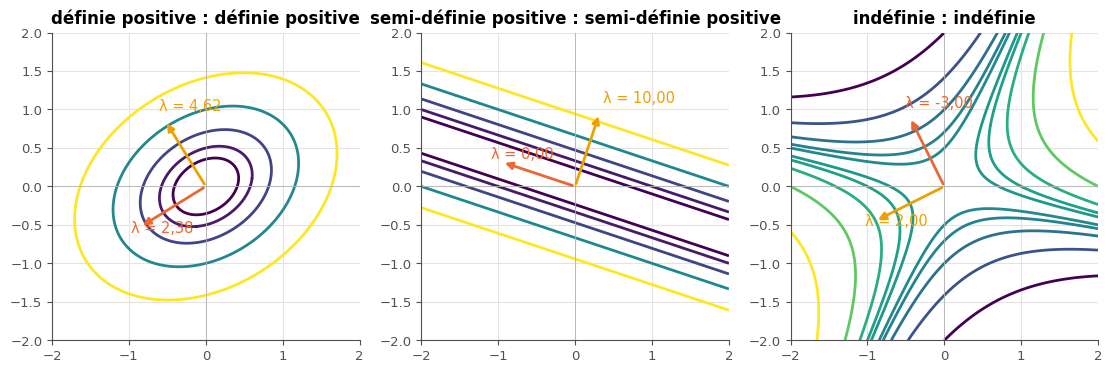

In [40]:
def classify(A):
    """The kind of the symmetric 2 × 2 matrix A, from the signs of its eigenvalues (zero within 1e-12 · max |λ|)."""
    values = np.linalg.eigvalsh(np.asarray(A, dtype=float))
    scale = max(1e-300, float(np.max(np.abs(values))))
    signs = {int(np.sign(v)) if abs(v) > 1e-12 * scale else 0 for v in values}
    if signs == {1}:
        return "définie positive"
    if signs == {-1}:
        return "définie négative"
    if -1 not in signs:
        return "semi-définie positive"
    if 1 not in signs:
        return "semi-définie négative"
    return "indéfinie"


def draw_levels(ax, A):
    """In ax: the level curves of xᵀAx on [-2, 2]², and the two unit eigenvectors of A as arrows."""
    A = np.asarray(A, dtype=float)
    grid = np.linspace(-2, 2, 201)
    X, Y = np.meshgrid(grid, grid)
    Q = A[0, 0] * X ** 2 + 2 * A[0, 1] * X * Y + A[1, 1] * Y ** 2
    levels = [v for v in (-8, -4, -2, -1, -0.5, 0.5, 1, 2, 4, 8) if Q.min() < v < Q.max()]
    ax.contour(X, Y, Q, levels=levels, cmap="viridis")
    values, vectors = np.linalg.eigh(A)
    for value, vector, color in zip(values, vectors.T, ("C1", "C3")):
        ax.annotate("", xy=vector, xytext=(0, 0), arrowprops={"arrowstyle": "-|>", "color": color, "lw": 2})
        ax.text(*(1.15 * vector), f"λ = {value:.2f}".replace(".", ","), color=color)
    ax.axhline(0, color="0.7", lw=0.6)
    ax.axvline(0, color="0.7", lw=0.6)
    ax.set_aspect("equal")


fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.6))
try:
    for ax, (name, A) in zip(axes, MATRICES_33.items()):
        draw_levels(ax, A)
        ax.set_title(f"{name} : {classify(A)}")
except BaseException:
    plt.close(fig)
    raise
plt.show()

**Vérifications automatiques** (sept autres matrices pour `classify`).

In [41]:
with checked("M12c.33 vérifications"):
    cases_33 = [([[2.0, 0.0], [0.0, 5.0]], "définie positive"), ([[0.0, 0.0], [0.0, 3.0]], "semi-définie positive"),
                ([[-2.0, 1.0], [1.0, -3.0]], "définie négative"), ([[0.0, 1.0], [1.0, 0.0]], "indéfinie"),
                ([[2.0, 6.0], [6.0, 18.0]], "semi-définie positive"), ([[1.0, 0.0], [0.0, 1e-9]], "définie positive"),
                ([[-0.1, -0.3], [-0.3, -0.9]], "semi-définie négative")]
    wrong_33 = [(A, expected, classify(np.array(A))) for A, expected in cases_33 if classify(np.array(A)) != expected]
    if wrong_33:
        A, expected, got = wrong_33[0]
        print(f"❌ Ex M12c.33 : classify({A}) rend {got!r}, on attendait {expected!r} : regarde les signes des valeurs "
              f"propres (np.linalg.eigvalsh), avec une tolérance pour zéro.")
    else:
        print("✅ Ex M12c.33 : classify range correctement sept matrices, dont trois semi-définies.")

✅ Ex M12c.33 : classify range correctement sept matrices, dont trois semi-définies.


💡 L'ellipse est la plus allongée le long du vecteur propre de la **plus petite** valeur propre : $q$ y monte le moins vite. Pour $\begin{pmatrix} 1 & 3 \\ 3 & 9 \end{pmatrix} = (1, 3)(1, 3)^\top$, $q(\mathbf{x}) = (x + 3y)^2$ est nulle sur la droite $x + 3y = 0$, le noyau. Pour l'indéfinie, $x^2 + 4xy - 2y^2 = 0$ donne deux droites, les asymptotes des hyperboles. $\operatorname{diag}(1 ;\ 10^{-9})$ a deux valeurs propres positives : définie positive, mais si près de la semi-définie qu'un arrondi peut la faire basculer (son conditionnement, M12d).

## Partie C · Erreurs classiques, savoir-faire et défi

Fiche §1, §3 à §7. Trois erreurs à trouver, une vérification avec SymPy, puis les trois plus grandes valeurs propres d'une grande matrice.

### Ex M12c.34 — Chasse à l'erreur : det(A + B) = det A + det B, un vecteur propre nul, Cholesky d'une matrice non symétrique 🐛 ★ ⏱️ 15 min
**Objectif :** repérer dans du code les erreurs classiques sur le déterminant, les vecteurs propres et Cholesky, puis calculer les bonnes valeurs.  
**Prérequis :** fiche §1, §3 et §7 · **Parcours :** C

Un collègue a écrit le code suivant ; six lignes portent une lettre et un commentaire qui dit ce qu'elles doivent calculer. Trois lignes ne calculent pas ce que dit leur commentaire. **Sans exécuter de code**, trouve-les.

```python
A = np.array([[1.0, 2.0], [3.0, 1.0]])
B = np.array([[2.0, 0.0], [1.0, -1.0]])
C = np.array([[4.0, 2.0], [-2.0, 5.0]])
x = np.array([1.0, 1.0])
d = np.linalg.det(A) + np.linalg.det(B)                   # (A) det(A + B)
t = np.trace(A) + np.trace(B)                             # (B) tr(A + B)
lam = 1 + np.sqrt(6)                                      # an eigenvalue of A
v = np.linalg.solve(A - lam * np.eye(2), np.zeros(2))     # (C) an eigenvector of A for lam: v[1] / v[0]
p = np.prod(np.linalg.eigvals(A))                         # (D) det A
L = np.linalg.cholesky(C)                                 # (E) the Cholesky factor of C, with C = L L^T: L[1, 0]
r = (x @ A @ x) / (x @ x)                                 # (F) the Rayleigh quotient of A at x
```

Questions :
- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) pour les lignes (A), (B), (C), (D) et (F), la bonne valeur de ce que dit leur commentaire (une liste de 5 nombres, 4 décimales) ;
- c) vrai ou faux : `np.linalg.cholesky(C)` lève une erreur.

Dans ta copie : pour chaque ligne fausse, quelle erreur a été faite, et comment la corriger ? Que rend la ligne (C), et pourquoi un résultat de ce genre devrait-il toujours alerter ? Que factorise réellement la ligne (E) ? Laquelle des trois est la plus dangereuse, et pourquoi ?

In [42]:
answer_M12c_34a = "ACE"
A = np.array([[1.0, 2.0], [3.0, 1.0]])
B = np.array([[2.0, 0.0], [1.0, -1.0]])
C = np.array([[4.0, 2.0], [-2.0, 5.0]])
x = np.array([1.0, 1.0])
d = np.linalg.det(A + B)                                  # (A) the determinant of the sum
t = np.trace(A) + np.trace(B)                             # (B) correct: the trace is linear
lam = 1 + np.sqrt(6)
v = np.array([2.0, lam - 1.0])                            # (C) (A − λI) v = 0: −√6 v₀ + 2 v₁ = 0
p = np.prod(np.linalg.eigvals(A))                         # (D) correct
r = (x @ A @ x) / (x @ x)                                 # (F) correct
answer_M12c_34b = [float(d), float(t), float(v[1] / v[0]), float(np.real(p)), float(r)]
try:
    np.linalg.cholesky(C)
    answer_M12c_34c = False
except np.linalg.LinAlgError:
    answer_M12c_34c = True
print(answer_M12c_34a, np.round(answer_M12c_34b, 4).tolist(), answer_M12c_34c)
print("what (C) returns:", np.linalg.solve(A - lam * np.eye(2), np.zeros(2)).tolist(),
      " what (E) returns:", np.linalg.cholesky(C).tolist())

ACE [-8.0, 3.0, 1.2247, -5.0, 3.5] False
what (C) returns: [0.0, 0.0]  what (E) returns: [[2.0, 0.0], [-1.0, 2.0]]


In [43]:
wbm.record("M12c.34a", "ACE",
           mistakes={"il manque une ligne fautive : refais chaque ligne à la main, avec ses propres nombres": "CE",
                     "il manque une ligne fautive : vérifie chaque résultat : un vecteur propre se vérifie en un produit": "AE",
                     "il manque une ligne fautive : regarde les hypothèses de chaque fonction appelée": "AC",
                     "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple": {"ABCE", "ACDE", "ACEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : refais chaque ligne à la main, avec ses propres nombres": {"BCE", "CDE", "CEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : vérifie chaque résultat : un vecteur propre se vérifie en un produit": {"ABE", "ADE", "AEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : regarde les hypothèses de chaque fonction appelée": {"ABC", "ACD", "ACF"},
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "C", "E"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"B", "D", "F", "AB", "AD", "AF", "BC", "BD", "BE", "BF", "CD", "CF", "DE", "DF", "EF", "ABD", "ABF", "ADF", "BCD", "BCF", "BDE", "BDF", "BEF", "CDF", "DEF", "ABCD", "ABCF", "ABDE", "ABDF", "ABEF", "ACDF", "ADEF", "BCDE", "BCDF", "BCEF", "BDEF", "CDEF", "ABCDF", "ABDEF", "BCDEF"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDE", "ABCEF", "ACDEF", "ABCDEF"}})
VALUES_34 = [-8.0, 3.0, float(np.sqrt(6) / 2), -5.0, 3.5]
wbm.record("M12c.34b", VALUES_34, decimals=4,
           mistakes={"(A) : le déterminant n'est pas additif, calcule det(A + B)": [-7.0] + VALUES_34[1:],
                      "(C) : un vecteur propre n'est jamais nul ; résous (A − λI) v = 0 à la main": VALUES_34[:2] + [0.0] + VALUES_34[3:]})
wbm.record("M12c.34c", False,
           mistakes={"np.linalg.cholesky ne vérifie pas la symétrie : elle ne lit que le triangle inférieur": True})

WBM_ANSWER {"hash": "869585c2a8e008c2aafc05018ea2662c298934a7707f02f5754438536460636d", "id": "M12c.34a", "kind": "str", "mistakes": {"0936531813fb20d38ee33b465f454475fd7a043f8dabf19bf21796e2b11e3c65": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0b9382b0fabaa13c355d4e95f1557314ddd5fe7d6c158e5e522fc23b9b5ee9ea": "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple", "0e84f7f9de9bf6b810a528263821ce674a151ba7de2ac1e78dd1ef8b57a43b6a": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0efa752fb1bebf8bb8c3453f75ba77103c8e512ee6c8055a72352fdefec6da03": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0f4419ceee7c761a4cedbcb10508b2d8ee2ce9df5d3103ff095f14c40b81c9ac": "il manque des lignes fautives, et des lignes que tu cites sont correctes : 

💡 (A) $\det(\mathbf{A} + \mathbf{B}) = \det\begin{pmatrix} 3 & 2 \\ 4 & 0 \end{pmatrix} = -8$, et non $-5 + (-2) = -7$. (C) $\mathbf{A} - \lambda\mathbf{I}$ est singulière en théorie, mais l'arrondi de $\lambda$ la rend inversible : `solve` rend la seule solution, $\mathbf{0}$ ; un vecteur propre nul doit toujours alerter. Le bon vecteur vérifie $-\sqrt{6}\,v_0 + 2v_1 = 0$ : $v_1/v_0 = \sqrt{6}/2$. (E) `cholesky` ne lit que le triangle inférieur : elle factorise $\begin{pmatrix} 4 & -2 \\ -2 & 5 \end{pmatrix}$ sans rien dire, alors que $\mathbf{C}$, non symétrique, n'a pas de décomposition de Cholesky. C'est la plus dangereuse : aucune erreur, un résultat plausible. (B), (D) et (F) sont justes : $3$, $(1 + \sqrt{6})(1 - \sqrt{6}) = -5$ et $\frac{7}{2}$.

### Ex M12c.35 — Vérifier avec SymPy : polynôme caractéristique, valeurs propres exactes, diagonalisation 🛠️ ★ ⏱️ 15 min
**Objectif :** vérifier un calcul de valeurs propres et une diagonalisation avec SymPy, en valeurs exactes, et reconnaître une matrice défective.  
**Prérequis :** fiche §3 et §4 ; R0 (SymPy) · **Parcours :** C

SymPy calcule en valeurs **exactes** : racines carrées et fractions restent écrites telles quelles, ce qui permet de vérifier un calcul papier sans arrondi. Avec les deux matrices fournies, écris :
- `charpoly_35` : le polynôme caractéristique $\det(\mathbf{M} - \lambda\mathbf{I})$ de `M35_DIAG`, en fonction du symbole `lam` (`(M35_DIAG - lam * sympy.eye(3)).det()`, puis `sympy.factor` pour le lire) ;
- `eigenvalues_35` : la liste de ses trois valeurs propres exactes (`sympy.solve(charpoly_35, lam)`, ou `M35_DIAG.eigenvals()`) ;
- `P_35, D_35` : la diagonalisation `M35_DIAG.diagonalize()` ;
- `diagonalizable_35` : `M35_DEFECTIVE.is_diagonalizable()`.

La cellule de vérification contrôle tes quatre résultats (✅ ou ❌, sans `wbm.check`).

Dans ta copie : écris les valeurs propres exactes de `M35_DIAG`, et vérifie que leur somme et leur produit sont la trace et le déterminant. Que rend `M35_DEFECTIVE.eigenvects()`, et pourquoi la matrice n'est-elle pas diagonalisable ? Pourquoi ne faut-il pas utiliser SymPy pour une matrice $100 \times 100$ ?

In [44]:
import sympy

M35_DIAG = sympy.Matrix([[2, 1, 0], [1, 2, 1], [0, 1, 2]])
M35_DEFECTIVE = sympy.Matrix([[2, 0, 1], [1, 3, 1], [1, 0, 2]])
lam = sympy.symbols("lambda")

In [45]:
charpoly_35 = (M35_DIAG - lam * sympy.eye(3)).det()
eigenvalues_35 = sympy.solve(charpoly_35, lam)
P_35, D_35 = M35_DIAG.diagonalize()
diagonalizable_35 = M35_DEFECTIVE.is_diagonalizable()
print("charpoly:", sympy.factor(charpoly_35), " eigenvalues:", eigenvalues_35)
print("D:", D_35.tolist(), " defective is diagonalizable:", diagonalizable_35, " eigenvects:", M35_DEFECTIVE.eigenvects())

with checked("M12c.35 vérifications"):
    problems_35, pending_35 = [], []
    reference_35 = (M35_DIAG - lam * sympy.eye(3)).det()
    if charpoly_35 is ...:
        pending_35.append("charpoly_35")
    else:
        expression_35 = charpoly_35.as_expr() if hasattr(charpoly_35, "as_expr") else charpoly_35
        if sympy.expand(expression_35 + reference_35) == 0:
            problems_35.append("charpoly_35 vaut det(λI − M), ce que rend .charpoly() : en dimension 3, c'est l'opposé de "
                               "det(M − λI) ; écris (M35_DIAG - lam * sympy.eye(3)).det()")
        elif sympy.expand(expression_35 - reference_35) != 0:
            problems_35.append("charpoly_35 doit être det(M − λI), en fonction du symbole lam")
    if eigenvalues_35 is ...:
        pending_35.append("eigenvalues_35")
    else:
        try:
            ok_values_35 = (sorted(eigenvalues_35, key=lambda e: float(e))
                            == sorted(sympy.roots(reference_35, lam).keys(), key=lambda e: float(e)))
        except (TypeError, ValueError):
            ok_values_35 = False
        if not ok_values_35:
            problems_35.append("eigenvalues_35 : les trois valeurs propres exactes de M35_DIAG (sympy.solve ou .eigenvals())")
    if P_35 is None or D_35 is None or P_35 is ... or D_35 is ...:
        pending_35.append("P_35, D_35")
    elif sympy.simplify(P_35 * D_35 * P_35.inv() - M35_DIAG) != sympy.zeros(3):
        problems_35.append("P_35 et D_35 : M35_DIAG.diagonalize() rend (P, D) avec M = P D P⁻¹")
    if diagonalizable_35 is ...:
        pending_35.append("diagonalizable_35")
    elif diagonalizable_35 is not False:
        problems_35.append("diagonalizable_35 : M35_DEFECTIVE.is_diagonalizable()")
    if problems_35:
        print("❌ Ex M12c.35 : à revoir : " + " ; ".join(problems_35) + "."
              + (f" (Pas encore fait : {', '.join(pending_35)}.)" if pending_35 else ""))
    elif pending_35:
        print("⏳ Ex M12c.35 : pas encore fait : " + ", ".join(pending_35) + ".")
    else:
        print("✅ Ex M12c.35 : polynôme caractéristique, valeurs propres exactes, diagonalisation et cas défectif vérifiés.")

charpoly: -(lambda - 2)*(lambda**2 - 4*lambda + 2)  eigenvalues: [2, 2 - sqrt(2), sqrt(2) + 2]
D: [[2, 0, 0], [0, 2 - sqrt(2), 0], [0, 0, sqrt(2) + 2]]  defective is diagonalizable: False  eigenvects: [(1, 1, [Matrix([
[-1],
[ 0],
[ 1]])]), (3, 2, [Matrix([
[0],
[1],
[0]])])]
✅ Ex M12c.35 : polynôme caractéristique, valeurs propres exactes, diagonalisation et cas défectif vérifiés.


💡 $\det(\mathbf{M} - \lambda\mathbf{I}) = (2 - \lambda)\big((2 - \lambda)^2 - 2\big)$ : valeurs propres $2$ et $2 \pm \sqrt{2}$, de somme 6 (la trace) et de produit $2 \times (4 - 2) = 4$ (le déterminant). La matrice défective a la valeur propre 3 double, mais $\mathbf{M} - 3\mathbf{I}$ est de rang 2 : un seul vecteur propre, $(0, 1, 0)$. SymPy calcule en exact : pour une grande matrice, les expressions explosent ; on prend NumPy.

### Ex M12c.36 — Défi : les trois plus grandes valeurs propres d'une matrice symétrique semi-définie positive 300 × 300, par la puissance avec déflation, à 1e−6 près 🏆 ★★★ ⏱️ 30 min
**Objectif :** trouver les plus grandes valeurs propres d'une grande matrice symétrique avec des produits matrice-vecteur seulement, par la méthode de la puissance et la déflation.  
**Prérequis :** fiche §5 et §6 ; Ex M12c.27 et M12c.32 · **Parcours :** C

La fonction fournie `make_spectrum_matrix(seed)` fabrique une matrice symétrique semi-définie positive $300 \times 300$, dont les trois plus grandes valeurs propres valent 10, 8 et 6,5, et les 297 autres sont entre 0 et 5 (tu ne connais pas ses vecteurs propres).

**L'objectif** : écrire `top_three(A)`, qui rend la liste de ses trois plus grandes valeurs propres, par ordre décroissant, à moins de $10^{-6}$ de celles de `np.linalg.eigvalsh` sur les trois matrices `seed` = 36, 37 et 38, **sans** `np.linalg.eigh`, `eigvalsh`, `eig`, `eigvals`, `svd`, ni `scipy`. Une dernière cellule enregistre si l'objectif est atteint.

Pistes (fiche §5 et §6) : la méthode de la puissance (ta fonction `power_iteration`, ou ta propre boucle) donne $\lambda_1$ et $\mathbf{q}_1$ ; la **déflation** $\mathbf{A} \leftarrow \mathbf{A} - \lambda_1\mathbf{q}_1\mathbf{q}_1^\top$ (produit extérieur : `np.outer`) remplace $\lambda_1$ par 0 sans changer les autres ; recommence. Pense au point de départ (pas orthogonal au vecteur cherché) et au nombre d'itérations : quel est le rapport $|\lambda_2/\lambda_1|$ à chaque étape ?

Dans ta copie : combien d'itérations demande chaque étape ? Laquelle devrait être la plus lente d'après les rapports $|\lambda_2/\lambda_1|$ de chaque étape, et l'observes-tu sur les trois matrices (le point de départ compte aussi) ? Pourquoi la déflation ne marcherait-elle pas telle quelle sur une matrice non symétrique ? Comment trouverais-tu la plus **petite** valeur propre avec la même méthode (indice : $c\mathbf{I} - \mathbf{A}$) ?

In [46]:
def make_spectrum_matrix(seed, n=300):
    """A symmetric positive semi-definite (n, n) matrix, of eigenvalues 10, 8, 6.5 and n − 3 others in [0, 5]."""
    rng = np.random.default_rng(seed)
    Q, _ = np.linalg.qr(rng.normal(size=(n, n)))
    values = np.concatenate([[10.0, 8.0, 6.5], rng.uniform(0.0, 5.0, size=n - 3)])
    A = (Q * values) @ Q.T
    return (A + A.T) / 2

In [47]:
mymath = wbm.load_mymath("ref")


def top_three(A):
    """The three largest eigenvalues of the symmetric positive semi-definite matrix A, in decreasing order."""
    A = np.array(A, dtype=float)
    start = np.random.default_rng(0).normal(size=A.shape[0])     # a random start: not orthogonal to q₁
    values = []
    for _ in range(3):
        value, vector, iterations = mymath.eigen.power_iteration(A, x0=start)
        values.append(value)
        A = A - value * np.outer(vector, vector)                  # deflation: λ is replaced by 0
    return values


print([round(v, 8) for v in top_three(make_spectrum_matrix(36))])

[10.0, 8.0, 6.5]


In [48]:
wbm.record("M12c.36", True,
           mistakes={"l'objectif n'est pas atteint sur les trois matrices : la cellule du défi dit pourquoi": False})

WBM_ANSWER {"hash": "73d3560dd5e64b3fd847248e0afb453e546ac103a6b7145fccc413f351601491", "id": "M12c.36", "kind": "bool", "mistakes": {"1ea54faafae1617fcb3ff27997d84337ceb32fbe761eb76c36270132b42758b4": "l'objectif n'est pas atteint sur les trois matrices : la cellule du défi dit pourquoi"}}
📝 Ex M12c.36 : réponse enregistrée (bool).


In [49]:
with checked("M12c.36 défi"):
    import inspect
    import re
    problems, ok_36, ran_36 = [], False, False
    try:
        source_36 = inspect.getsource(top_three)
    except (OSError, TypeError):
        source_36 = ""
    banned_36 = sorted(set(re.findall(r"\b(eigh|eigvalsh|eig|eigvals|svd|scipy)\b", source_36)))
    if banned_36:
        ran_36 = True
        problems.append(f"top_three utilise {', '.join(banned_36)}, interdit dans ce défi : la méthode de la puissance "
                        f"et la déflation seulement")
    for seed_t in ((36, 37, 38) if not banned_36 else ()):
        A_t = make_spectrum_matrix(seed_t)
        expected = np.linalg.eigvalsh(A_t)[::-1][:3]
        try:
            got = np.asarray(top_three(A_t.copy()), dtype=float)
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001
            ran_36 = True
            problems.append(f"top_three lève {type(exc).__name__} ({exc})")
            break
        ran_36 = True
        if got.shape != (3,):
            problems.append(f"matrice {seed_t} : top_three rend la forme {got.shape}, pas (3,)")
            break
        gap = float(np.max(np.abs(got - expected)))
        print(f"matrice {seed_t} : {np.round(got, 8).tolist()}, écart à eigvalsh {gap:.1e}")
        if not gap <= 1e-6:
            problems.append(f"matrice {seed_t} : écart {gap:.1e} à eigvalsh, au-dessus de 1e-6")
            break
    if problems:
        print("❌ Ex M12c.36 : " + " ; ".join(problems) + ".")
    else:
        ok_36 = True
        print("✅ Ex M12c.36 : défi réussi : les trois plus grandes valeurs propres à moins de 1e-6, sur les trois matrices.")

matrice 36 : [10.0, 8.0, 6.5], écart à eigvalsh 7.1e-15


matrice 37 : [10.0, 8.0, 6.5], écart à eigvalsh 3.6e-15
matrice 38 : [10.0, 8.0, 6.5], écart à eigvalsh 8.9e-15
✅ Ex M12c.36 : défi réussi : les trois plus grandes valeurs propres à moins de 1e-6, sur les trois matrices.


💡 Les rapports successifs sont $8/10 = 0{,}8$, $6{,}5/8 \approx 0{,}81$ et environ $5/6{,}5 \approx 0{,}77$ (la plus grande des valeurs restantes est proche de 5) : quelques dizaines à une centaine d'itérations par étape pour le vecteur, et la valeur propre d'une matrice symétrique converge deux fois plus vite. Pour une matrice non symétrique, $\mathbf{A} - \lambda_1\mathbf{v}_1\mathbf{v}_1^\top$ ne garde pas les autres vecteurs propres (ils ne sont pas orthogonaux à $\mathbf{v}_1$). La plus petite valeur propre : la plus grande de $c\mathbf{I} - \mathbf{A}$ avec $c \ge \lambda_{\max}$, ou la méthode appliquée à $\mathbf{A}^{-1}$ (itération inverse).

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu calculer un déterminant et l'interpréter comme un volume orienté ?
2. Sais-tu calculer les valeurs et vecteurs propres d'une petite matrice, et diagonaliser ?
3. Sais-tu appliquer le théorème spectral et le quotient de Rayleigh à une matrice symétrique ?
4. Sais-tu programmer et régler la méthode de la puissance ?
5. Sais-tu reconnaître une matrice définie positive, calculer sa décomposition de Cholesky, et blanchir une covariance ?

**La suite** : M12d, la SVD et l'analyse en composantes principales, puis le chapitre 12 de workbookIA (préparation des données).